In [2]:
import numpy as np              # Одномерные и многомерные массивы
import pandas as pd             # Таблицы (dataframe, series)
import matplotlib.pyplot as plt # Графика
import seaborn as sns           # Графика для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 40)

RANDOM_STATE = 42               # для воспроизводимости результатов
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.6.1 | pandas 2.2.3


# Предсказание популярности игр в Steam

## 0. Описание задачи

Цель работы - по информации со страницы игры в магазине Steam (цена, жанры, теги, платформы, языки, описание, дата выхода и т.д.) предсказать, насколько большой будет аудитория игры, то есть сколько людей её купят или установят.

Steam не раскрывает точное число владельцев, в датасете указан только диапазон (`Estimated owners`, например «20000 – 50000»). Редкие верхние диапазоны объединены в 4 класса, поэтому это **задача многоклассовой классификации**:

- `0` — игры до 20 тыс. владельцев;
- `1` — малые (20–100 тыс.);
- `2` — средние (100 тыс. – 1 млн);
- `3` — хиты (больше 1 млн).

Классы сильно несбалансированы: хитов всего около 2 %.

Практический смысл: разработчик или издатель ещё до выхода игры может оценить её потенциальную аудиторию по тому, как она оформлена в магазине.

Стоит отметить, что число отзывов, пиковый онлайн, число рекомендаций и время игры - это *следствия* популярности, а не её причины, и до выхода игры они неизвестны. Поэтому для обучения они не используются.

Источник данных: [Steam Games Dataset (FronkonGames, Kaggle)](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset).

# 1. Чтение данных

Файл `games.csv` (около 400 МБ) лежит на Google Диске. В заголовке файла есть известная ошибка: столбец `DiscountDLC count` на самом деле состоит из двух столбцов (`Discount` и `DLC count`). Из-за этого названий на одно меньше, чем значений в строке, поэтому нужно исправить заголовок вручную.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

PATH = '/content/drive/MyDrive/ML_2026_DATASET/games.csv'


cols = pd.read_csv(PATH, nrows=0).columns.tolist()
i = cols.index('DiscountDLC count')
cols = cols[:i] + ['Discount', 'DLC count'] + cols[i + 1:]

data_raw = pd.read_csv(PATH, header=0, names=cols, index_col=False)
data_raw.shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(125855, 40)

In [8]:
data_raw.head(3)

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,[],[],NaN,https://shared.akamai.steamstatic.co...,NaN,NaN,NaN,True,False,False,0,NaN,0,0,0,NaN,0,0,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.co...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry t...",['English'],[],NaN,https://shared.akamai.steamstatic.co...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,0,NaN,0,252,3,NaN,0,231,NaN,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,St...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.co...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,Immerse yourself in the most beloved...,"['English', 'French', 'German', 'Rus...",[],NaN,https://shared.akamai.steamstatic.co...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,0,NaN,0,21,3,NaN,0,0,NaN,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hi...",https://shared.akamai.steamstatic.co...,NaN


In [9]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  object 
 2   Release date                125855 non-null  object 
 3   Estimated owners            125855 non-null  object 
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  object 
 10  Supported languages         125855 non-null  object 
 11  Full audio languages        125855 non-null  object 
 12  Reviews                     12181 non-null   object 
 13  Header image  

**Вывод.** В таблице 125 855 игр и 40 столбцов: 15 целочисленных, 3 вещественных, 3 логических (платформы) и 19 строковых. Строковые столбцы - это тексты, списки категорий, ссылки и даты.

Пропуски есть во многих столбцах:
- `Movies` пуст полностью, `Score rank` заполнен только у 40 игр - эти столбцы бесполезны;
- ссылка на Metacritic есть лишь у 3,4 % игр, цитаты из обзоров (`Reviews`) у 9,7 %, примечания (`Notes`) у 18,5 %, сайт (`Website`) у 40 %;
- теги (`Tags`) отсутствуют у трети игр, описание, разработчик, издатель, жанры и категории - примерно у 7 %.

Кроме явных пропусков (`NaN`), есть **скрытые**: оценка Metacritic `0` означает «оценки нет», пустой список языков записан как строка `[]`. Дата выхода хранится как строка (`Aug 1, 2023`), её нужно будет перевести в числа. Все эти особенности будут обработаны в следующих пунктах.

Описание столбцов:

| Столбец | Тип | Смысл |
|---|---|---|
| `AppID`, `Name` | идентификатор | номер и название игры (для обучения не нужны) |
| `Estimated owners` | целевая | диапазон числа владельцев |
| `Release date` | дата | дата выхода |
| `Required age` | числовой | возрастное ограничение (0 - для всех) |
| `Price`, `Discount` | числовой | цена в долларах и текущая скидка в % |
| `DLC count`, `Achievements` | числовой | число дополнений и достижений |
| `Metacritic score` | числовой | оценка критиков (0 = оценки нет) |
| `Windows`, `Mac`, `Linux` | бинарный | поддерживаемые платформы |
| `Developers`, `Publishers` | категориальный | разработчик и издатель |
| `Genres`, `Tags`, `Categories` | список категорий | жанры, пользовательские теги, возможности (одиночная игра, кооператив, достижения…) |
| `Supported languages`, `Full audio languages` | список категорий | языки интерфейса и озвучки |
| `About the game` | текст | описание игры |
| `Reviews`, `Notes` | текст | цитаты из обзоров, примечания о контенте |
| `Screenshots`, `Movies` | список ссылок | скриншоты и видео (полезно только их количество) |
| `Header image`, `Website`, `Support url`, `Support email`, `Metacritic url` | ссылки | для модели бесполезны (кроме факта наличия) |
| `Peak CCU`, `Positive`, `Negative`, `Recommendations`, `User score`, `Score rank`, `Average/Median playtime …` | числовой | онлайн, отзывы, время игры - **следствия популярности, в модель не включаем** |

# 2. Разбиение на обучающую и тестовую выборки

Сначала уберём «мусорные» записи: игры, у которых меньше 10 отзывов. Многие из них заброшены или почти никому не видны, а диапазон владельцев для них оценён очень грубо.

Затем переведём диапазоны `Estimated owners` в 4 класса.

Разбиваем данные до всех преобразований: пороги выбросов, медианы для пропусков, параметры нормализации считаем только по обучающей выборке, иначе информация из теста «просочится» в модель. Пропорция 3:1 (`test_size=0.25`). Так как классы несбалансированы, разбиение **стратифицированное** (`stratify`): доли классов в обеих частях одинаковые.

In [10]:
from sklearn.model_selection import train_test_split

# оставляем игры хотя бы с 10 отзывами
data = data_raw[(data_raw['Positive'] + data_raw['Negative']) >= 10].copy()
print('Игр после фильтрации:', data.shape[0])

# диапазон владельцев -> класс (по верхней границе диапазона)
def owners_to_class(s):
    upper = int(s.split(' - ')[1])
    if upper <= 20_000:
        return 0
    elif upper <= 100_000:
        return 1
    elif upper <= 1_000_000:
        return 2
    else:
        return 3

data['target'] = data['Estimated owners'].apply(owners_to_class)
class_names = ['Нишевые (до 20 тыс.)', 'Малые (20–100 тыс.)',
               'Средние (0,1–1 млн)', 'Хиты (> 1 млн)']

# проверка: каждый диапазон попал в свой класс
print(pd.crosstab(data['Estimated owners'], data['target']))
data = data.drop(columns=['Estimated owners'])

train, test = train_test_split(data, test_size=0.25, random_state=RANDOM_STATE,
                               stratify=data['target'])
y_train, y_test = train['target'], test['target']

print('\nОбучающая выборка:', train.shape[0], '| тестовая:', test.shape[0])
print(pd.DataFrame({'train, %': y_train.value_counts(normalize=True).sort_index() * 100,
                    'test, %':  y_test.value_counts(normalize=True).sort_index() * 100})
        .set_axis(class_names).round(1))

Игр после фильтрации: 56662
target                     0     1     2    3
Estimated owners                             
0 - 20000              34193     0     0    0
100000 - 200000            0     0  3268    0
1000000 - 2000000          0     0     0  725
10000000 - 20000000        0     0     0   51
100000000 - 200000000      0     0     0    4
20000 - 50000              0  9190     0    0
200000 - 500000            0     0  2786    0
2000000 - 5000000          0     0     0  404
20000000 - 50000000        0     0     0   31
50000 - 100000             0  4731     0    0
500000 - 1000000           0     0  1145    0
5000000 - 10000000         0     0     0  125
50000000 - 100000000       0     0     0    9

Обучающая выборка: 42496 | тестовая: 14166
                      train, %  test, %
Нишевые (до 20 тыс.)      60.3     60.3
Малые (20–100 тыс.)       24.6     24.6
Средние (0,1–1 млн)       12.7     12.7
Хиты (> 1 млн)             2.4      2.4


**Вывод.** После отсева игр, у которых меньше 10 отзывов, осталось 56 662 игры (45 % исходного датасета). Таблица сопряжённости подтверждает, что каждый исходный диапазон попал ровно в один класс.

Обучающая выборка - 42 496 игр, тестовая - 14 166. Благодаря стратификации доли классов в обеих частях совпадают: 60,3 % / 24,6 % / 12,7 % / 2,4 %. Классы сильно несбалансированы: нишевых игр в 25 раз больше, чем хитов. Поэтому доля верных ответов (accuracy) будет плохой мерой качества: модель, которая всегда отвечает «нишевая», уже получит около 60 %.

# 3. Визуализация данных и основные характеристики

Все графики и статистики строим только по обучающей выборке.

## 3.1. Баланс классов

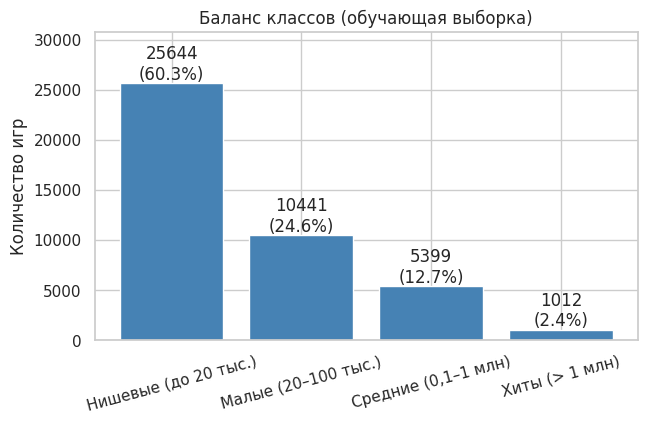

Соотношение самого большого и самого маленького класса: 25 : 1


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = y_train.value_counts().sort_index()
ax.bar(class_names, counts.values, color='steelblue')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v}\n({v / len(y_train):.1%})', ha='center', va='bottom')
ax.set_ylabel('Количество игр')
ax.set_title('Баланс классов (обучающая выборка)')
ax.set_ylim(0, counts.max() * 1.2)
plt.xticks(rotation=15)
plt.show()

print(f'Соотношение самого большого и самого маленького класса: {counts.max() / counts.min():.0f} : 1')

**Вывод.** В обучающей выборке 25 644 нишевые игры (60,3 %), 10 441 малая (24,6 %), 5 399 средних (12,7 %) и только 1 012 хитов (2,4 %). Самый большой класс в 25 раз больше самого маленького. Это нормально для рынка: большинство игр в Steam покупают единицы тысяч человек, а миллионной аудитории достигают немногие. Из-за дисбаланса оценивать модель только по accuracy нельзя: нужны метрики по каждому классу (precision, recall, F1), и особенно важно, находит ли модель хиты.

## 3.2. Числовые признаки, извлечённые из строк

Многие полезные сведения хранятся в строках, и модель напрямую их не поймёт. Нужно извлечь числа:
- из даты выхода - год и месяц;
- из списков (языки, жанры, теги, категории, скриншоты) - число элементов;
- из описания игры - его длину в символах;
- из ссылок и текстов - факт наличия (есть ли сайт, цитаты из обзоров, примечания о контенте);
- из цены - признак «бесплатная игра».

Одну и ту же функцию применяем к обучающей и тестовой выборкам.

In [22]:
def count_items(s):
    """Число элементов в строке-списке ('Action,Indie' -> 2, "['English']" -> 1, пусто -> 0)."""
    s = s.fillna('').astype(str).str.strip('[]').str.strip()
    return s.apply(lambda x: len([t for t in x.split(',') if t.strip()]))


def add_features(d):
    d = d.copy()
    date = pd.to_datetime(d['Release date'], format='mixed', errors='coerce')
    d['release_year'] = date.dt.year
    d['release_month'] = date.dt.month
    d['n_languages'] = count_items(d['Supported languages'])
    d['n_audio_languages'] = count_items(d['Full audio languages'])
    d['n_genres'] = count_items(d['Genres'])
    d['n_tags'] = count_items(d['Tags'])
    d['n_categories'] = count_items(d['Categories'])
    d['n_screenshots'] = count_items(d['Screenshots'])
    d['about_len'] = d['About the game'].fillna('').str.len()
    d['is_free'] = (d['Price'] == 0).astype(int)
    d['has_website'] = d['Website'].notna().astype(int)
    d['has_reviews'] = d['Reviews'].notna().astype(int)
    d['has_notes'] = d['Notes'].notna().astype(int)
    for c in ['Windows', 'Mac', 'Linux']:
        d[c] = d[c].astype(int)
    return d


train = add_features(train)
test = add_features(test)

# признаки, которые пойдут в модель
num_cols = ['Price', 'Discount', 'Required age', 'DLC count', 'Achievements', 'Metacritic score',
            'release_year', 'release_month', 'n_languages', 'n_audio_languages',
            'n_genres', 'n_tags', 'n_categories', 'n_screenshots', 'about_len']
bin_cols = ['Windows', 'Mac', 'Linux', 'is_free', 'has_website', 'has_reviews', 'has_notes']
# «признаки-следствия» популярности: смотрим на них в анализе, но в модель не берём
leak_cols = ['Peak CCU', 'Positive', 'Negative', 'Recommendations',
             'Average playtime forever', 'Median playtime forever']

train[num_cols + bin_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Price,42496.0,5.23,10.66,0.0,0.99,2.99,6.39,299.99
Discount,42496.0,27.64,32.76,0.0,0.00,0.00,55.00,100.00
Required age,42496.0,0.30,2.20,0.0,0.00,0.00,0.00,18.00
DLC count,42496.0,0.90,20.59,0.0,0.00,0.00,0.00,3703.00
Achievements,42496.0,29.19,206.75,0.0,0.00,11.00,27.00,5000.00
Metacritic score,42496.0,5.42,19.45,0.0,0.00,0.00,0.00,96.00
release_year,42496.0,2019.89,3.50,1997.0,2017.00,2020.00,2023.00,2025.00
release_month,42496.0,6.55,3.42,1.0,4.00,7.00,10.00,12.00
n_languages,42496.0,5.24,10.35,0.0,1.00,2.00,6.00,103.00
n_audio_languages,42496.0,1.70,8.09,0.0,0.00,0.00,1.00,103.00


**Вывод.** Основные характеристики:
- **Цена:** медиана 2,99, среднее 5,23, максимум 299,99. Стандартное отклонение (10,66) вдвое больше среднего, то есть распределение сильно скошено вправо: много дешёвых игр и немного очень дорогих. Бесплатных игр 13 %.
- **DLC и достижения:** у большинства игр дополнений нет (медиана 0), но максимум 3 703 DLC. Медиана достижений 11, а максимум 5 000. Это явные выбросы.
- **Оценка Metacritic:** даже 75-й процентиль равен 0, то есть у подавляющего большинства игр оценки нет. Среднее 5,42 смысла не имеет: это скрытые пропуски, обработаем их в пункте 5.
- **Год выхода:** от 1997 до 2025, медиана 2020. Дата распозналась у всех игр.
- **Языки:** медиана 2 языка, но максимум 103.
- **Теги:** медиана 18, максимум 21 (Steam показывает до 20 тегов).
- **Длина описания:** медиана около 1 160 символов, максимум 67 520.
- **Бинарные признаки:** Windows поддерживают практически все игры (среднее 1,00, без Windows всего 5 игр), поэтому этот признак бесполезен. Mac поддерживают 23 % игр, Linux 16 %, сайт есть у 54 %, цитаты из обзоров у 18 %.

У многих признаков среднее заметно больше медианы, а максимум на порядки больше 75-го процентиля. Это признак тяжёлых «хвостов» и выбросов.

## 3.3. Распределения числовых признаков

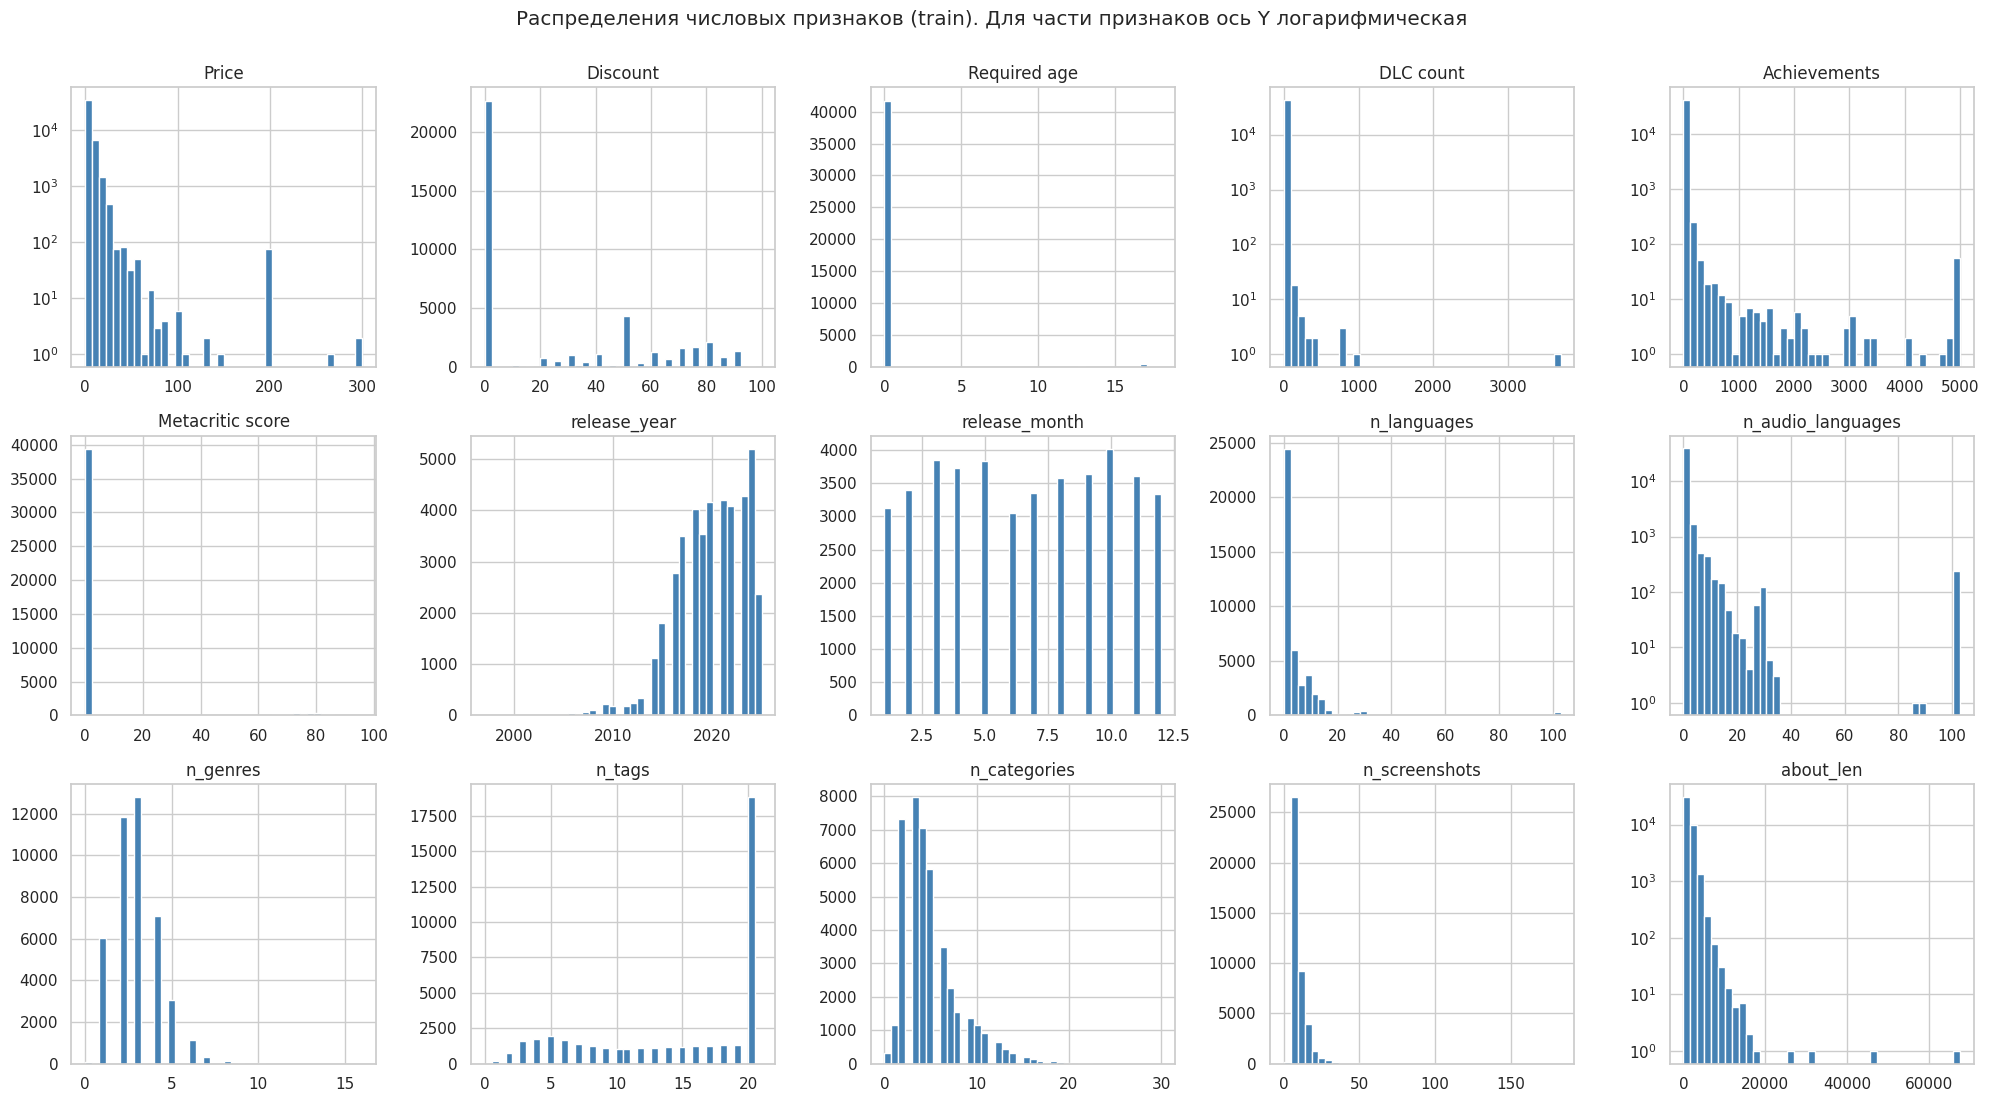

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(train[c].dropna(), bins=40, color='steelblue')
    ax.set_title(c)
    if c in ['Price', 'DLC count', 'Achievements', 'about_len', 'n_audio_languages']:
        ax.set_yscale('log')
plt.suptitle('Распределения числовых признаков (train). Для части признаков ось Y логарифмическая', y=1.0)
plt.tight_layout()
plt.show()

**Вывод.** Большинство признаков распределены сильно несимметрично, с длинным правым хвостом (цена, DLC, достижения, языки, скриншоты, длина описания). Заметны необычные «пики»:
- около 80 игр с ценой около 200 $;
- около 50 игр ровно с 5 000 достижений. Это максимум, разрешённый Steam, так делают «игры-накрутки» достижений;
- примерно 250 игр с озвучкой более чем на 100 языках. Это нереалистично: скорее всего, разработчики просто отметили все языки из списка.

Число тегов имеет пик на 20: это верхний предел, который показывает Steam. Год выхода показывает быстрый рост числа игр после 2014 года (Steam упростил публикацию); 2025 год представлен не полностью, так как данные собраны в течение года. Месяц выхода распределён почти равномерно. Скидка у половины игр равна 0, а у остальных разбросана от 20 до 90 %. Это скидка на момент сбора данных, поэтому она во многом случайна.

## 3.4. Признаки в разных классах

Сравним распределения признаков у нишевых игр и у хитов. Выбросы на графиках скрыты, чтобы были видны сами «ящики».

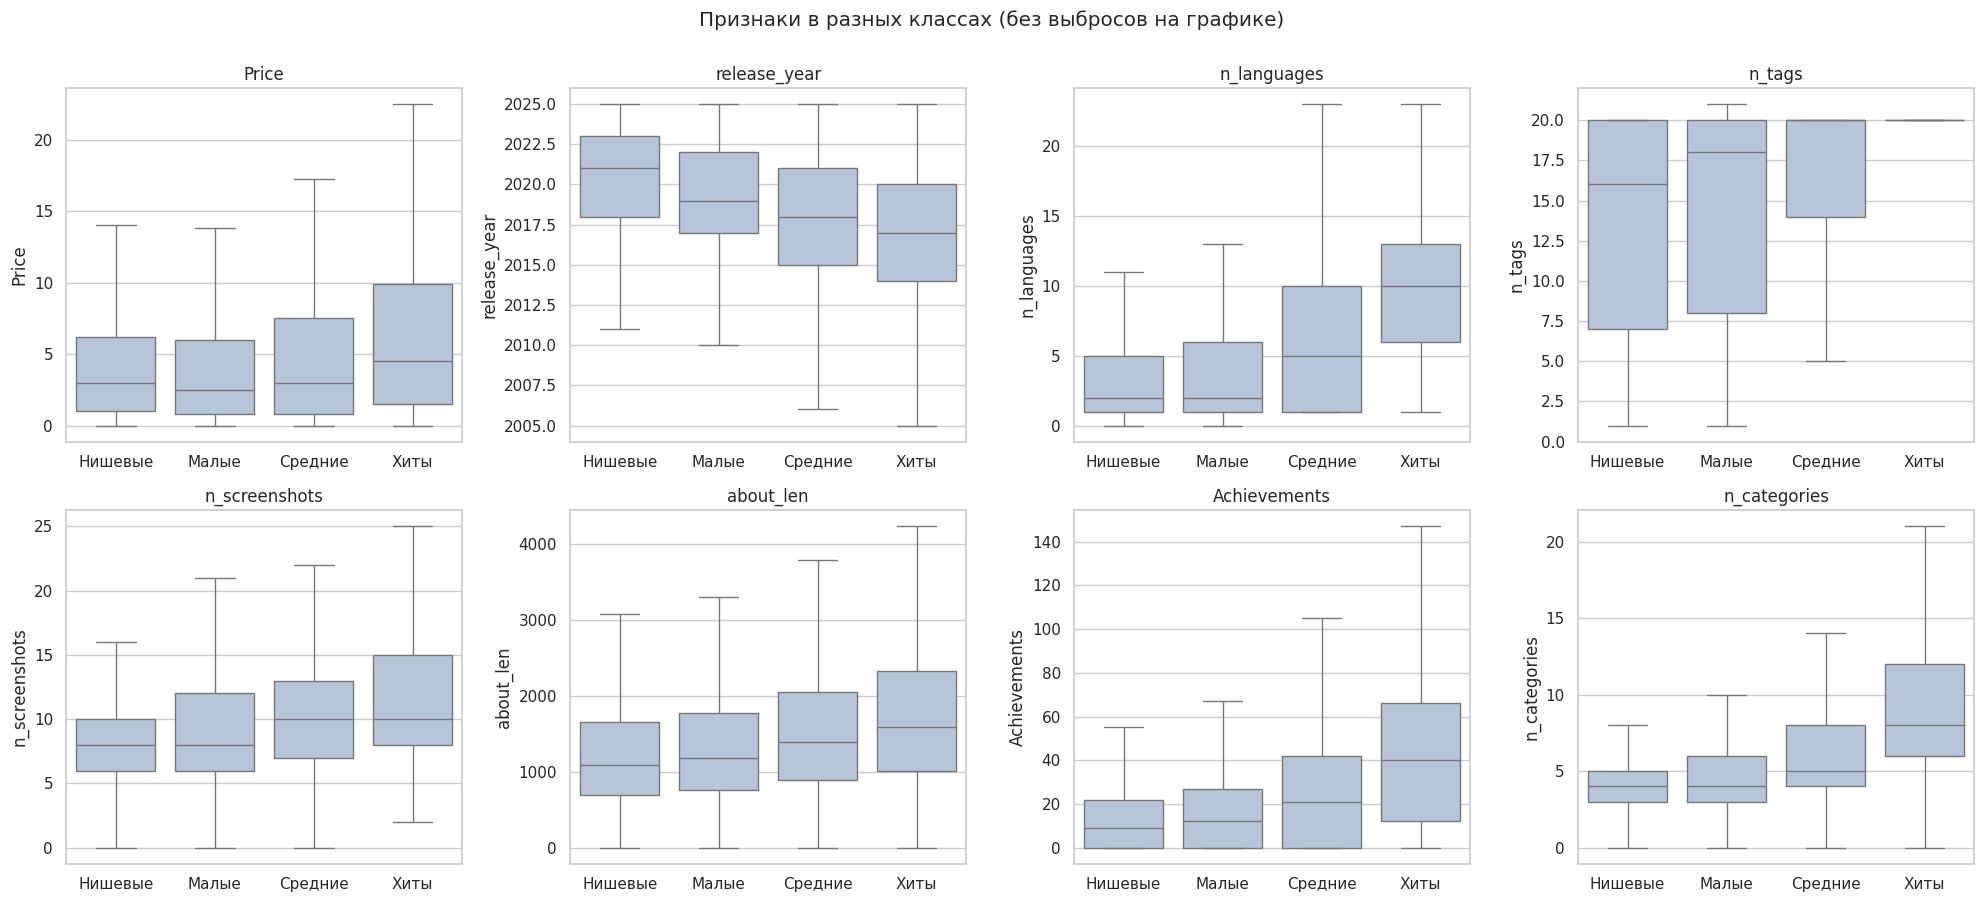

Медианы признаков по классам:


,Price,release_year,n_languages,n_tags,n_screenshots,about_len,Achievements,n_categories
Нишевые (до 20 тыс.),3.0,2021.0,2.0,16.0,8.0,1091.0,9.0,4.0
Малые (20–100 тыс.),2.5,2019.0,2.0,18.0,8.0,1178.0,12.0,4.0
"Средние (0,1–1 млн)",3.0,2018.0,5.0,20.0,10.0,1392.0,21.0,5.0
Хиты (> 1 млн),4.5,2017.0,10.0,20.0,10.0,1592.0,40.0,8.0


In [19]:
show = ['Price', 'release_year', 'n_languages', 'n_tags', 'n_screenshots',
        'about_len', 'Achievements', 'n_categories']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(x=y_train, y=train[c], ax=ax, showfliers=False, color='lightsteelblue')
    ax.set_xticklabels(['Нишевые', 'Малые', 'Средние', 'Хиты'])
    ax.set_xlabel('')
    ax.set_title(c)
plt.suptitle('Признаки в разных классах (без выбросов на графике)', y=1.0)
plt.tight_layout()
plt.show()

print('Медианы признаков по классам:')
train.groupby(y_train)[show].median().set_axis(class_names).round(1)

**Вывод.** Почти все признаки монотонно меняются от нишевых игр к хитам:
- **Год выхода:** медиана у нишевых игр 2021, у хитов 2017. Чем старше игра, тем дольше она набирала аудиторию.
- **Языки:** медиана 2 у нишевых и малых игр, 5 у средних, 10 у хитов. Локализация на много языков расширяет аудиторию, к тому же её могут позволить себе крупные проекты.
- **Теги:** у хитов почти всегда ровно 20. Теги проставляют сами игроки, поэтому у популярной игры их всегда максимум.
- **Категории и достижения:** медианы растут с 4 до 8 и с 9 до 40.
- **Скриншоты и длина описания:** растут слабее (с 8 до 10 и примерно с 1 090 до 1 590 символов). Хиты в среднем оформлены тщательнее.
- **Цена** почти не различается (медиана 2,5–4,5 $), только у хитов разброс шире.


## 3.5. Жанры, теги и бинарные признаки

Для каждого жанра и тега посчитаем, какая доля игр с ним оказалась средней или хитом (классы 2 и 3). Красная пунктирная линия - доля по всей обучающей выборке. В скобках указано число игр (`n`).

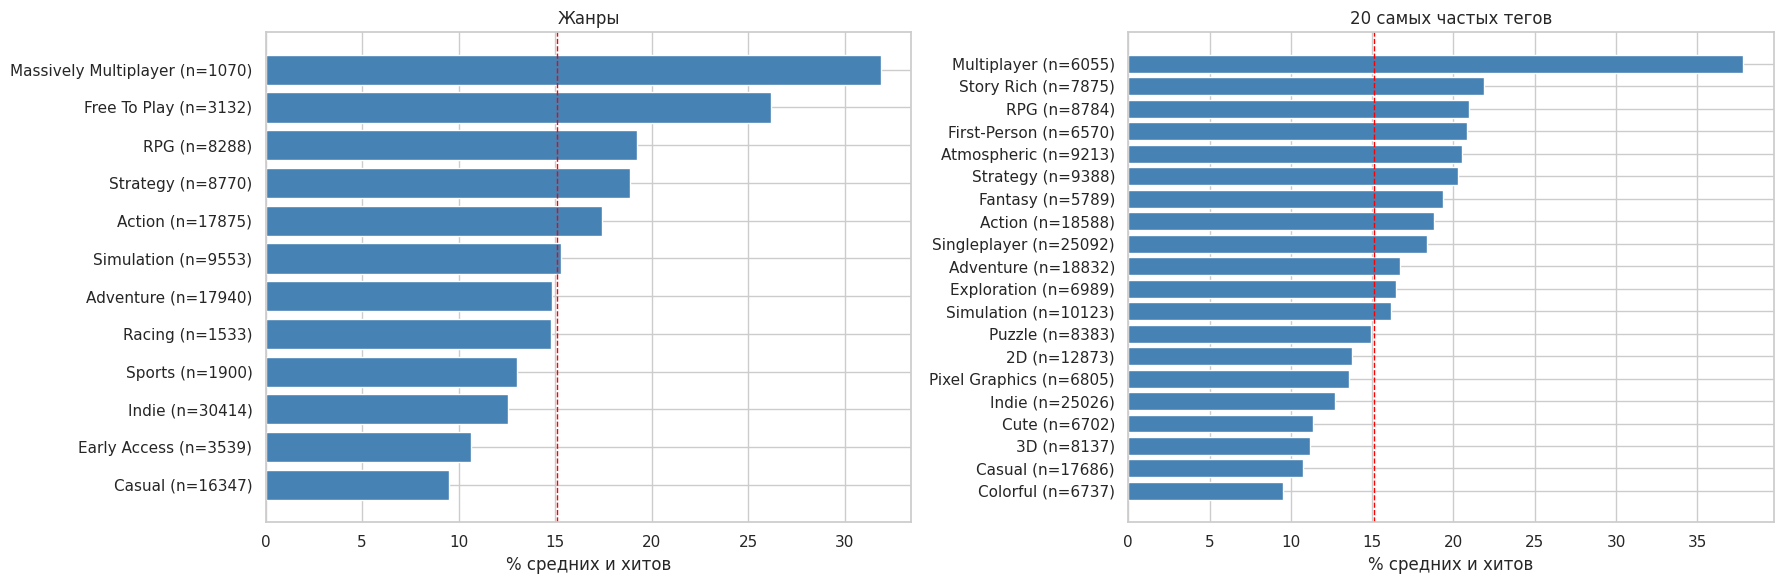

,признак,значение,игр,% средних и хитов
0,Windows,0,5,20.0
1,Windows,1,42491,15.1
2,Mac,0,32618,13.2
3,Mac,1,9878,21.3
4,Linux,0,35675,13.9
5,Linux,1,6821,21.0
6,is_free,0,37025,14.3
7,is_free,1,5471,20.5
8,has_website,0,19377,8.6
9,has_website,1,23119,20.5


In [20]:
def plot_share(ax, col, top=12, title=None):
    items = train[col].fillna('').str.split(',').explode().str.strip()
    items = items[items != '']
    rows = []
    for it in items.value_counts().head(top).index:
        idx = items[items == it].index.unique()
        rows.append({'item': it, 'n': len(idx), 'share': (y_train.loc[idx] >= 2).mean() * 100})
    g = pd.DataFrame(rows).sort_values('share')
    ax.barh([f'{a} (n={n})' for a, n in zip(g['item'], g['n'])], g['share'], color='steelblue')
    ax.axvline((y_train >= 2).mean() * 100, color='red', ls='--', lw=1)
    ax.set_xlabel('% средних и хитов')
    ax.set_title(title or col)


fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plot_share(axes[0], 'Genres', title='Жанры')
plot_share(axes[1], 'Tags', top=20, title='20 самых частых тегов')
plt.tight_layout()
plt.show()

rows = []
for c in bin_cols:
    for v in [0, 1]:
        m = train[c] == v
        rows.append({'признак': c, 'значение': v, 'игр': m.sum(),
                     '% средних и хитов': (y_train[m] >= 2).mean() * 100})
pd.DataFrame(rows).round(1)

**Вывод.** В среднем средних игр и хитов 15,1 % (красная линия).
- **Жанры.** Сильнее всего выделяются массовые многопользовательские игры (Massively Multiplayer, около 32 %) и бесплатные (Free To Play, около 26 %): бесплатная игра привлекает больше установок. Выше среднего также RPG, Strategy и Action. Ниже среднего Casual (около 9,5 %), Early Access (около 10,6 %) и Indie (около 12,5 %): это в основном небольшие проекты.
- **Теги.** Лидирует Multiplayer (около 38 %), далее Story Rich, RPG, First-Person, Atmospheric (20–22 %). Ниже среднего «простые» визуальные теги: Colorful, Casual, 3D, Cute, Indie, Pixel Graphics, 2D.
- **Бинарные признаки.** Если у игры есть сайт, доля средних и хитов в 2,4 раза выше (20,5 % против 8,6 %). Если есть цитаты из обзоров, в 2,3 раза выше (28,4 % против 12,2 %). Поддержка Mac и Linux повышает долю примерно в 1,5 раза (около 21 % против 13–14 %): портирование на другие системы делают более крупные проекты. Бесплатные игры чаще популярны (20,5 % против 14,3 %).

## 3.6. Корреляционная матрица

Используем коэффициент корреляции **Спирмена**. Он учитывает только порядок значений, поэтому не так чувствителен к выбросам, а у нас распределения сильно скошены.

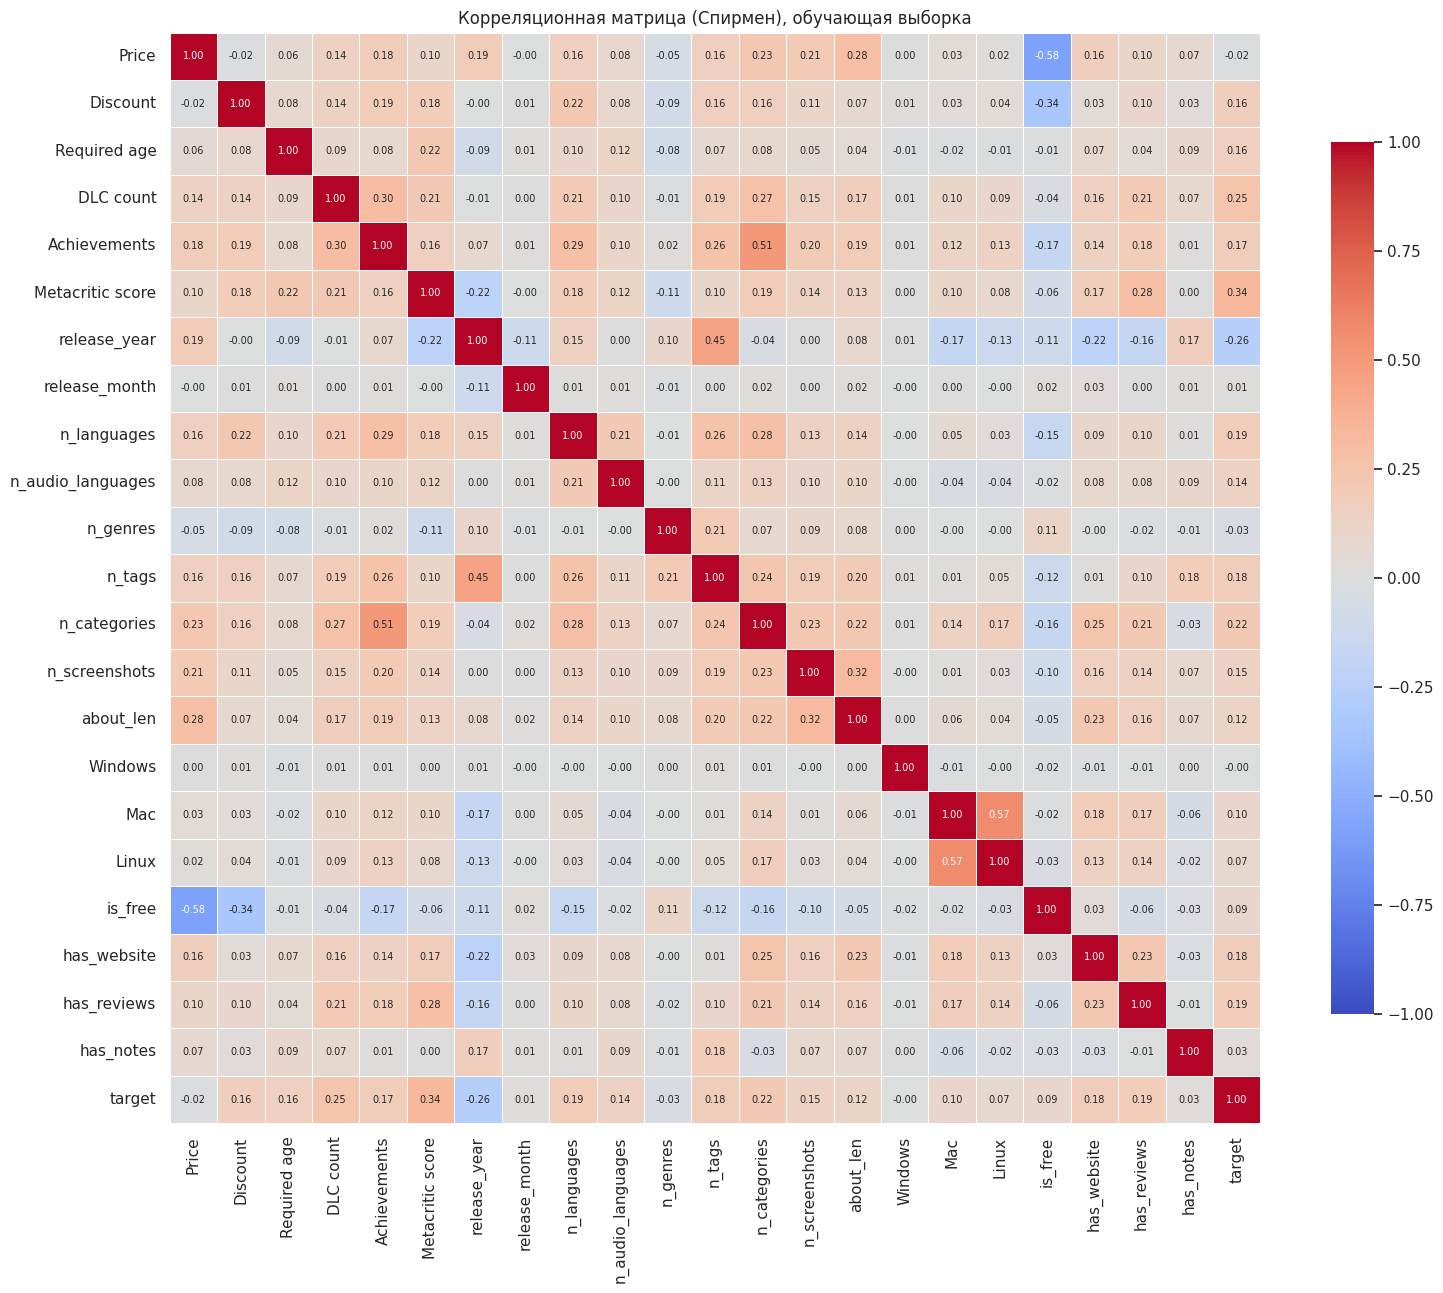

Корреляция признаков с классом:
release_year        -0.263
n_genres            -0.033
Price               -0.016
Windows             -0.000
release_month        0.011
has_notes            0.031
Linux                0.072
is_free              0.086
Mac                  0.099
about_len            0.125
n_audio_languages    0.135
n_screenshots        0.148
Required age         0.161
Discount             0.164
Achievements         0.173
has_website          0.175
n_tags               0.175
has_reviews          0.187
n_languages          0.188
n_categories         0.216
DLC count            0.254
Metacritic score     0.335
Name: target, dtype: float64


In [16]:
corr = train[num_cols + bin_cols + ['target']].corr(method='spearman')

plt.figure(figsize=(16, 13))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, annot_kws={'size': 7}, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица (Спирмен), обучающая выборка')
plt.tight_layout()
plt.show()

print('Корреляция признаков с классом:')
print(corr['target'].drop('target').sort_values().round(3))

**Вывод.** Связь отдельных признаков с классом слабая: самая сильная корреляция по модулю около 0,34.
- Сильнее всего связаны оценка Metacritic (0,34; в основном за счёт того, есть ли оценка вообще), год выхода (−0,26; старые игры популярнее), число DLC (0,25) и категорий (0,22).
- Далее с корреляцией 0,15–0,19 идут число языков, наличие цитат из обзоров, сайта, число тегов, достижений, скидка, возрастное ограничение и скриншоты.
- Цена (−0,02), число жанров (−0,03), месяц выхода (0,01) и Windows (0,00) с классом почти не связаны.

Между собой признаки тоже коррелируют умеренно. Самые заметные пары: цена и «бесплатная игра» (−0,58, связь очевидна), Mac и Linux (0,57: если портируют, то обычно сразу на обе системы), достижения и число категорий (0,51: «Steam Achievements» — одна из категорий), год выхода и число тегов (0,45). Пар с корреляцией больше 0,6 нет, поэтому сильно дублирующих друг друга признаков нет.

Связь каждого отдельного признака с классом слабая. Но это не значит, что слабыми будут и модели: много слабых признаков вместе могут дать заметно лучший результат, чем любой из них по отдельности. Проверим это в пунктах 8–10.

## 3.7. Почему не используем отзывы, онлайн и время игры

Проверим, насколько сильно «признаки-следствия» популярности связаны с классом.

Корреляция «признаков-следствий» с классом (Спирмен):
Negative                    0.646
Positive                    0.638
Recommendations             0.593
Average playtime forever    0.588
Median playtime forever     0.556
Peak CCU                    0.477
dtype: float64


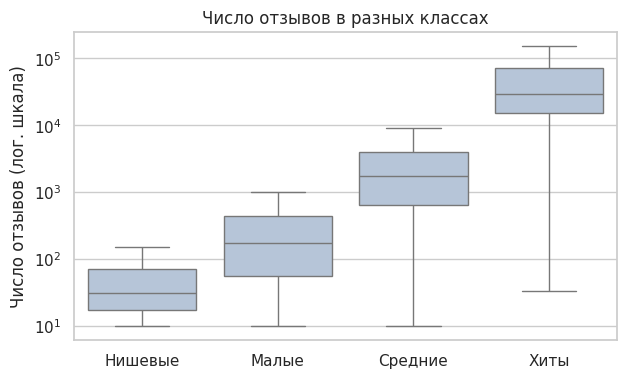

In [21]:
leak_corr = train[leak_cols].corrwith(y_train, method='spearman').sort_values(ascending=False)
print('Корреляция «признаков-следствий» с классом (Спирмен):')
print(leak_corr.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=y_train, y=train['Positive'] + train['Negative'], ax=ax,
            showfliers=False, color='lightsteelblue')
ax.set_yscale('log')
ax.set_xticklabels(['Нишевые', 'Малые', 'Средние', 'Хиты'])
ax.set_xlabel('')
ax.set_ylabel('Число отзывов (лог. шкала)')
ax.set_title('Число отзывов в разных классах')
plt.show()

**Вывод.** Признаки-следствия связаны с классом в 2 раза сильнее, чем лучший «честный» признак: корреляция числа отрицательных и положительных отзывов около 0,64–0,65, рекомендаций и времени игры 0,56–0,59, пикового онлайна 0,48. На графике медианное число отзывов растёт на порядок от класса к классу: около 30 у нишевых, около 170 у малых, около 1 700 у средних и около 30 000 у хитов. Ящики почти не перекрываются.

Причина в том, что число владельцев оценивается в основном по числу отзывов. Если дать эти признаки модели, она будет просто пересчитывать отзывы во владельцев, и точность будет высокой, но бесполезной: до выхода игры отзывов нет. Поэтому в модель эти признаки не берём.

# 4. Выбросы

Бинарные признаки выбросов не имеют. Выбросы ищем в числовых признаках со скошенным распределением по правилу межквартильного размаха (IQR): выбросом считаем значение вне интервала $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$. Заодно проверим, отличается ли среди выбросов доля средних игр и хитов.

,Q1,Q3,верхняя граница IQR,99-й процентиль,максимум,% выбросов (IQR),% средних и хитов среди выбросов,% средних и хитов среди остальных
признак,,,,,,,,
Price,1.0,6.4,14.5,30.0,300.0,7.5,21.5,14.6
DLC count,0.0,0.0,0.0,10.0,3703.0,22.5,30.7,10.5
Achievements,0.0,27.0,67.5,135.1,5000.0,5.0,36.2,14.0
n_languages,1.0,6.0,13.5,30.0,103.0,6.7,27.3,14.2
n_audio_languages,0.0,1.0,2.5,27.0,103.0,8.3,32.8,13.5
n_screenshots,6.0,11.0,18.5,31.0,183.0,6.2,24.5,14.5
about_len,741.0,1755.0,3276.0,4939.1,67520.0,4.5,23.7,14.7
n_categories,3.0,6.0,10.5,16.0,30.0,7.1,34.6,13.6
n_genres,2.0,4.0,7.0,7.0,16.0,0.4,13.6,15.1


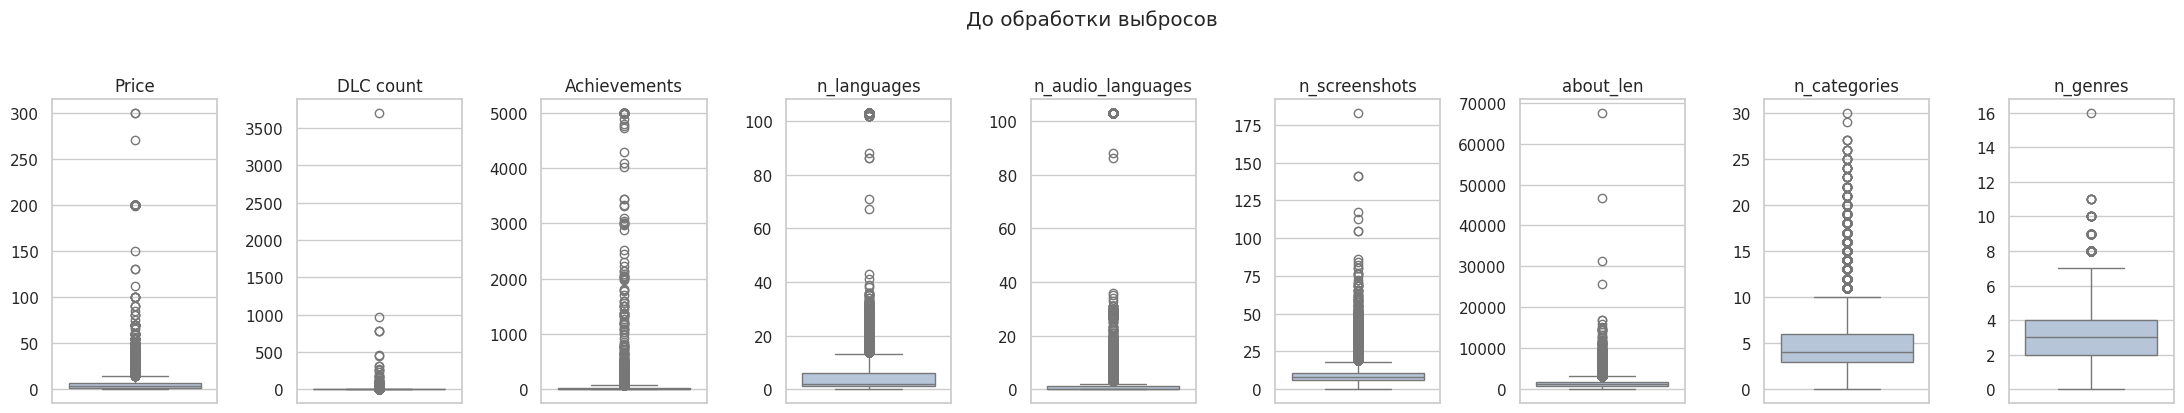

In [23]:
out_cols = ['Price', 'DLC count', 'Achievements', 'n_languages', 'n_audio_languages',
            'n_screenshots', 'about_len', 'n_categories', 'n_genres']

rows = []
for c in out_cols:
    s = train[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    is_out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    rows.append({'признак': c, 'Q1': q1, 'Q3': q3,
                 'верхняя граница IQR': q3 + 1.5 * iqr,
                 '99-й процентиль': s.quantile(0.99), 'максимум': s.max(),
                 '% выбросов (IQR)': is_out.mean() * 100,
                 '% средних и хитов среди выбросов': (y_train[is_out] >= 2).mean() * 100,
                 '% средних и хитов среди остальных': (y_train[~is_out] >= 2).mean() * 100})
display(pd.DataFrame(rows).set_index('признак').round(1))

fig, axes = plt.subplots(1, len(out_cols), figsize=(22, 4))
for ax, c in zip(axes, out_cols):
    sns.boxplot(y=train[c], ax=ax, color='lightsteelblue')
    ax.set_title(c)
    ax.set_ylabel('')
plt.suptitle('До обработки выбросов', y=1.03)
plt.tight_layout()
plt.show()

**Вывод.** По правилу IQR выбросами оказываются от 4,5 % (длина описания) до 8,3 % (языки озвучки) значений. Для `DLC count` правило не работает: у большинства игр 0 DLC, поэтому $Q_1 = Q_3 = 0$, и «выбросом» считается любая игра хотя бы с одним дополнением (22,5 %). Для признаков, где большая часть значений равна нулю, правило IQR не подходит.

Главное наблюдение заключается в том, что среди выбросов доля средних игр и хитов в 1,5–2,5 раза выше, чем среди остальных. Например, у игр с аномально большим числом категорий она 34,6 % против 13,6 %, у игр с большим числом достижений 36,2 % против 14,0 %. Выбросы здесь не ошибки, а в основном крупные проекты: у них больше языков, DLC, достижений и скриншотов. Исключение — число жанров: там выбросов всего 0,4 %, и класс от них не зависит.

Максимумы при этом бывают совершенно нереальными: 3 703 DLC, 5 000 достижений, 103 языка, описание в 67 520 символов, цена 300 $.

Экстремальные значения (3 703 DLC, 5 000 достижений, описание в 67 тысяч символов) сильно искажают нормализацию и расстояния в методе ближайших соседей. Поэтому ограничим их сверху: значения выше 99-го процентиля заменим на сам 99-й процентиль (винсоризация). Снизу обрезать не нужно, там естественная граница 0. Границы считаем только по обучающей выборке и применяем к обеим.

Верхние границы (99-й процентиль train):
Price                  29.99
DLC count              10.00
Achievements          135.05
n_languages            30.00
n_audio_languages      27.00
n_screenshots          31.00
about_len            4939.05
n_categories           16.00
n_genres                7.00
Name: 0.99, dtype: float64


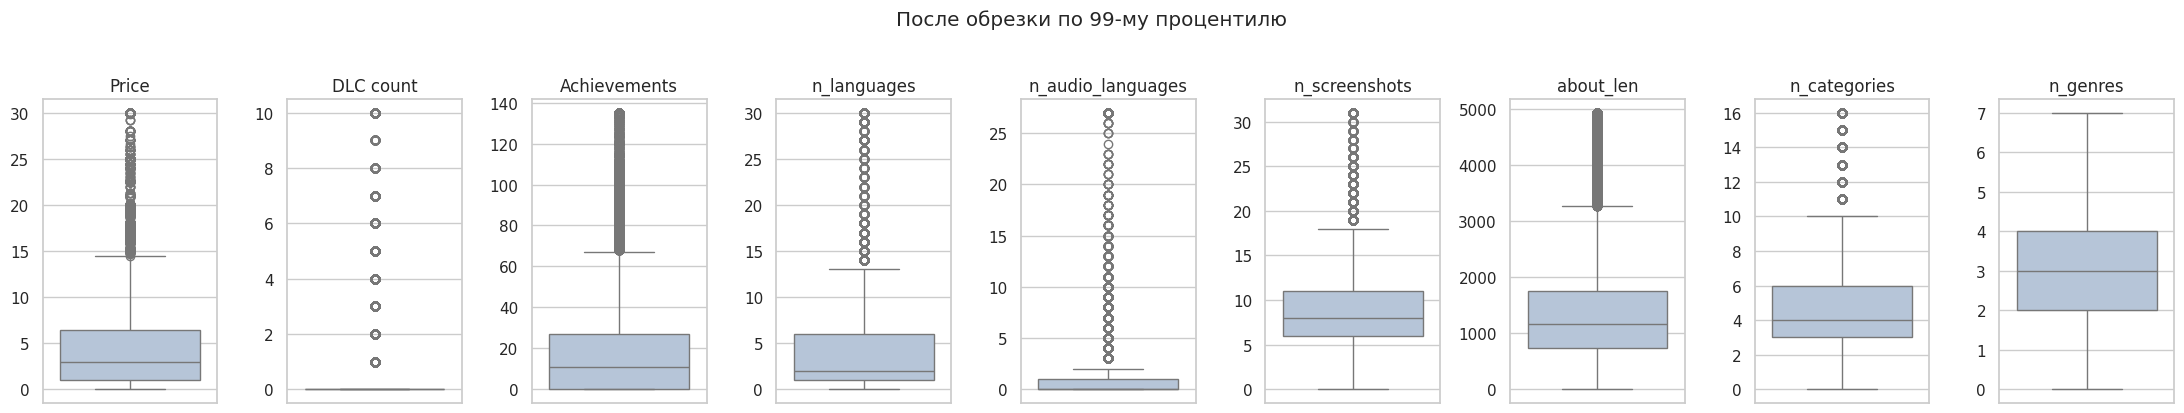

In [24]:
high = train[out_cols].quantile(0.99)
train[out_cols] = train[out_cols].clip(upper=high, axis=1)
test[out_cols] = test[out_cols].clip(upper=high, axis=1)

print('Верхние границы (99-й процентиль train):')
print(high.round(2))

fig, axes = plt.subplots(1, len(out_cols), figsize=(22, 4))
for ax, c in zip(axes, out_cols):
    sns.boxplot(y=train[c], ax=ax, color='lightsteelblue')
    ax.set_title(c)
    ax.set_ylabel('')
plt.suptitle('После обрезки по 99-му процентилю', y=1.03)
plt.tight_layout()
plt.show()

**Вывод.** После обрезки по 99-му процентилю максимумы стали разумными: цена не больше 29,99 $, DLC не больше 10, достижений не больше 135, языков интерфейса не больше 30, озвучки не больше 27, скриншотов не больше 31, длина описания не больше примерно 4 900 символов, категорий не больше 16, жанров не больше 7. Точки за «усами» на графиках остались: это значения выше границы IQR, но ниже 99-го процентиля. Мы их сохранили сознательно, потому что они несут информацию о классе. Строки не удалялись, изменился только 1 % самых больших значений в каждом признаке.

# 5. Обработка пропущенных значений

Кроме явных пропусков (`NaN`), учитываем скрытые: оценка Metacritic или пользователей равна 0, список языков пуст (`[]`). Для каждого столбца посмотрим долю пропусков и то, отличается ли доля средних и хитов среди игр с пропуском.

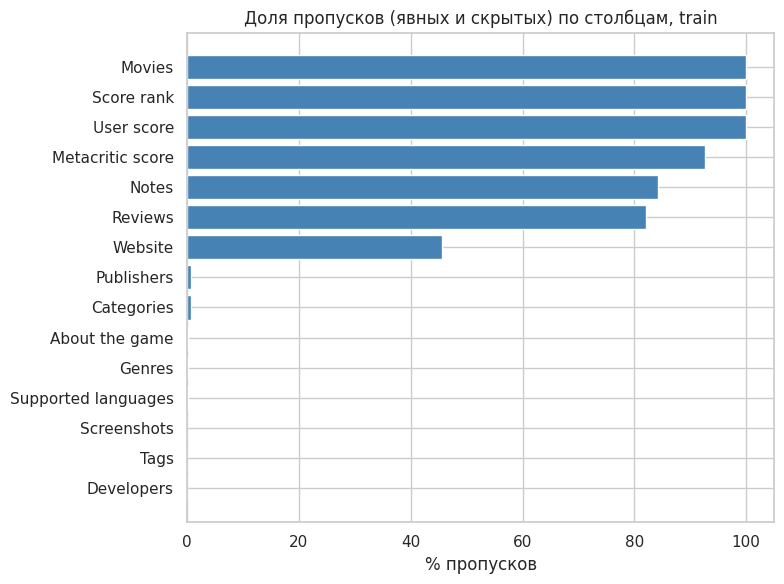

,% пропусков,% средних и хитов среди пропусков,% средних и хитов среди заполненных
Developers,0.0,0.0,15.1
Tags,0.0,100.0,15.1
Screenshots,0.0,18.8,15.1
Supported languages,0.1,0.0,15.1
Genres,0.2,23.1,15.1
About the game,0.2,31.9,15.1
Categories,0.7,6.5,15.1
Publishers,0.7,12.9,15.1
Website,45.6,8.6,20.5
Reviews,82.1,12.2,28.4


In [25]:
check = pd.DataFrame({
    'About the game':      train['About the game'].isna(),
    'Developers':          train['Developers'].isna(),
    'Publishers':          train['Publishers'].isna(),
    'Genres':              train['Genres'].isna(),
    'Categories':          train['Categories'].isna(),
    'Tags':                train['Tags'].isna(),
    'Supported languages': train['n_languages'] == 0,
    'Screenshots':         train['Screenshots'].isna(),
    'Website':             train['Website'].isna(),
    'Reviews':             train['Reviews'].isna(),
    'Notes':               train['Notes'].isna(),
    'Metacritic score':    train['Metacritic score'] == 0,
    'User score':          train['User score'] == 0,
    'Score rank':          train['Score rank'].isna(),
    'Movies':              train['Movies'].isna(),
})
miss = pd.DataFrame({
    '% пропусков': check.mean() * 100,
    '% средних и хитов среди пропусков':   [(y_train[check[c]] >= 2).mean() * 100 for c in check],
    '% средних и хитов среди заполненных': [(y_train[~check[c]] >= 2).mean() * 100 for c in check],
}).sort_values('% пропусков')

plt.figure(figsize=(8, 6))
plt.barh(miss.index, miss['% пропусков'], color='steelblue')
plt.xlabel('% пропусков')
plt.title('Доля пропусков (явных и скрытых) по столбцам, train')
plt.tight_layout()
plt.show()

miss.round(1)

**Вывод.** Пропуски сильно различаются по столбцам:
- `Movies`, `Score rank` и `User score` пусты почти полностью (99,9–100 %), информации в них нет.
- Оценки Metacritic нет у 92,7 % игр, примечаний (`Notes`) у 84,3 %, цитат из обзоров (`Reviews`) у 82,1 %, сайта у 45,6 %.
- В остальных столбцах пропусков меньше 1 %. Интересно, что у игр с 10 и более отзывами теги заполнены почти всегда, хотя во всём датасете их не было у трети игр: теги ставят игроки, и у игр без аудитории их просто нет.

Сам факт пропуска несёт информацию. Если у игры есть оценка Metacritic, она оказывается средней или хитом в 61,2 % случаев, а если нет — только в 11,4 %, то есть в 5 раз реже. Сайт: 20,5 % против 8,6 %, цитаты из обзоров: 28,4 % против 12,2 %. Поэтому пропуски нельзя просто удалить или заполнить средним, нужно сохранить информацию о том, что значение отсутствовало.

Способы обработки:
- `Movies`, `Score rank`, `User score` пустые или почти пустые, в модель не идут (как и остальные признаки-следствия).
- `Website`, `Reviews`, `Notes` в модель целиком не берём, от них остаются индикаторы наличия (`has_website`, `has_reviews`, `has_notes`) из пункта 3.2. Так информация о пропуске сохраняется.
- **Оценка Metacritic:** нули заменяем на `NaN`, добавляем индикатор `has_metacritic` (есть ли оценка), а пропуски заполняем медианой оценок из обучающей выборки.
- **Описание, языки, скриншоты:** у отсутствующего значения длина и количество уже равны 0. Для тегов добавим индикатор `has_tags`.
- **Разработчик, издатель, жанры, теги, категории:** пропуски заполняем отдельным значением `Unknown`, чтобы не придумывать несуществующих данных.
- **Остальные числовые признаки** (например, год выхода, если дата в тестовой выборке не распознается) заполняем медианой обучающей выборки.

In [26]:
from sklearn.impute import SimpleImputer

for d in (train, test):
    d['has_metacritic'] = (d['Metacritic score'] > 0).astype(int)
    d['Metacritic score'] = d['Metacritic score'].replace(0, np.nan)
    d['has_tags'] = d['Tags'].notna().astype(int)

# числовые признаки: медиана по обучающей выборке
imp_num = SimpleImputer(strategy='median').fit(train[num_cols])
print('Медианы, которыми заполняем пропуски:')
print(pd.Series(imp_num.statistics_, index=num_cols)[['Metacritic score', 'release_year', 'release_month']])
train[num_cols] = imp_num.transform(train[num_cols])
test[num_cols] = imp_num.transform(test[num_cols])

# категориальные и списки: отдельное значение 'Unknown'
cat_cols = ['Developers', 'Publishers']
list_cols = ['Genres', 'Tags', 'Categories']
for d in (train, test):
    d[cat_cols + list_cols] = d[cat_cols + list_cols].fillna('Unknown')

# Windows убираем (почти константа), добавляем новые индикаторы
bin_cols = [c for c in bin_cols if c != 'Windows'] + ['has_metacritic', 'has_tags']

feature_cols = num_cols + bin_cols + cat_cols + list_cols
print('\nПропусков в признаках для модели: train =', int(train[feature_cols].isna().sum().sum()),
      '| test =', int(test[feature_cols].isna().sum().sum()))

Медианы, которыми заполняем пропуски:
Metacritic score      75.0
release_year        2020.0
release_month          7.0
dtype: float64

Пропусков в признаках для модели: train = 0 | test = 0


**Вывод.** Пропуски в оценке Metacritic заполнены медианой оценок обучающей выборки (75), а сам факт наличия оценки сохранён в признаке `has_metacritic`. Год и месяц выхода распознались у всех игр, медианы (2020 год, июль) нужны только как страховка для тестовой выборки. Категориальные признаки и списки дополнены значением `Unknown`. Теперь в признаках для модели нет пропусков ни в обучающей, ни в тестовой выборке.

Индикатор `has_tags` оказался почти постоянным (у отобранных игр теги есть практически всегда), поэтому в пункте 7 мы его уберём.

# 6. Обработка категориальных признаков

Два вида признаков.

**Обычные категориальные: разработчик и издатель.** Уникальных значений тысячи. One-hot кодирование дало бы тысячи почти пустых столбцов, и для метода ближайших соседей это плохо, так как расстояние «размывается». Поэтому используем **частотное кодирование**: заменяем название компании на число *других* игр этой компании в обучающей выборке. Это осмысленная величина, размер «портфолио»: у крупных издателей вроде Ubisoft или Sega много игр, у инди-студии обычно одна. Для обучающей выборки вычитаем 1 (саму игру), чтобы смысл признака был одинаковым для train и test. Подсчёт делаем только по обучающей выборке.

Добавим бинарный признак `self_published`: разработчик сам издаёт свою игру (обычно это маленькие независимые студии).

In [32]:
print('Число уникальных значений (train):')
print(train[cat_cols].nunique())
print('\nСамые частые издатели:')
print(train['Publishers'].value_counts().head(10))

for col, new in [('Developers', 'developer_games'), ('Publishers', 'publisher_games')]:
    vc = train[col].value_counts()
    vc['Unknown'] = 0                       # неизвестную компанию считаем «без других игр»
    train[new] = train[col].map(vc) - (train[col] != 'Unknown').astype(int)
    test[new] = test[col].map(vc).fillna(0)  # компания, которой нет в train -> 0

for d in (train, test):
    d['self_published'] = ((d['Developers'] == d['Publishers']) &
                           (d['Developers'] != 'Unknown')).astype(int)

print('\nСреднее по классам:')
train.groupby(y_train)[['developer_games', 'publisher_games', 'self_published']].mean() \
     .set_axis(class_names).round(2)

Число уникальных значений (train):
Developers    27902
Publishers    23146
dtype: int64

Самые частые издатели:
Publishers
Unknown              311
BFG Entertainment    156
Kagura Games         134
Conglomerate 5       131
Strategy First       117
Sekai Project        110
Choice of Games      107
THQ Nordic           107
Laush Studio         106
HH-Games             101
Name: count, dtype: int64

Среднее по классам:


,developer_games,publisher_games,self_published
Нишевые (до 20 тыс.),3.85,9.44,0.70
Малые (20–100 тыс.),3.60,13.17,0.59
"Средние (0,1–1 млн)",3.32,17.26,0.49
Хиты (> 1 млн),4.15,23.29,0.45


**Вывод.** В обучающей выборке 27 902 разных разработчика и 23 146 издателей, поэтому one-hot кодирование действительно не подходит. Самые «плодовитые» издатели (BFG Entertainment, Kagura Games, Conglomerate 5, Strategy First, Sekai Project, Choice of Games, THQ Nordic и др.) выпустили по 100–160 игр. В основном это издатели недорогих казуальных игр, визуальных новелл и переизданий. Издатель неизвестен у 311 игр.

Размер портфолио издателя заметно растёт от класса к классу: в среднем 9,4 других игры у издателя нишевой игры, 13,2 у малой, 17,3 у средней и 23,3 у хита. Крупный издатель вкладывает в продвижение больше ресурсов. Доля игр, которые разработчик издаёт сам, наоборот падает: с 70 % у нишевых до 45 % у хитов. По размеру портфолио разработчика явной зависимости нет (3,3–4,2 игры во всех классах).

**Списки категорий: жанры, теги, категории.** У одной игры может быть несколько жанров сразу («Action, Indie, RPG»), поэтому обычный one-hot не подходит. Применяем **multi-hot кодирование**: для каждого значения заводим столбец 0/1, и у игры единицы стоят во всех столбцах её жанров. Это делает `MultiLabelBinarizer`.

Чтобы не плодить сотни редких столбцов, оставляем:
- жанры и категории, которые встречаются хотя бы у 1 % игр обучающей выборки;
- 20 самых частых тегов (те, что были рассмотрены в пункте 3.5). Всего тегов несколько сотен, а редкие только добавляют шум в расстояние.

Список значений фиксируем по обучающей выборке. Значения, которых в нём нет, в тестовой выборке просто игнорируются.

In [33]:
from sklearn.preprocessing import MultiLabelBinarizer


def split_list(s):
    """'Action,Indie' -> ['Action', 'Indie'] (значение 'Unknown' отбрасываем)."""
    return s.apply(lambda x: [t.strip() for t in str(x).split(',')
                              if t.strip() and t.strip() != 'Unknown'])


top_n = {'Genres': None, 'Tags': 20, 'Categories': None}   # None -> порог 1 % игр
min_share = 0.01
mlb = {}
for col in list_cols:
    items = split_list(train[col]).explode().dropna().value_counts()
    keep = items.head(top_n[col]).index if top_n[col] else items[items >= min_share * len(train)].index
    mlb[col] = MultiLabelBinarizer(classes=sorted(keep))
    mlb[col].fit([])
    print(f'{col}: всего значений {len(items)}, оставляем {len(keep)}')


def multi_hot(d):
    parts = []
    for col in list_cols:
        m = mlb[col].transform(split_list(d[col]))
        parts.append(pd.DataFrame(m, columns=[f'{col}_{c}' for c in mlb[col].classes_], index=d.index))
    return pd.concat(parts, axis=1)


mh_train = multi_hot(train)
mh_test = multi_hot(test)
print('\nВсего multi-hot столбцов:', mh_train.shape[1])
print(list(mh_train.columns))

Genres: всего значений 28, оставляем 12
Tags: всего значений 451, оставляем 20
Categories: всего значений 57, оставляем 40

Всего multi-hot столбцов: 72
['Genres_Action', 'Genres_Adventure', 'Genres_Casual', 'Genres_Early Access', 'Genres_Free To Play', 'Genres_Indie', 'Genres_Massively Multiplayer', 'Genres_RPG', 'Genres_Racing', 'Genres_Simulation', 'Genres_Sports', 'Genres_Strategy', 'Tags_2D', 'Tags_3D', 'Tags_Action', 'Tags_Adventure', 'Tags_Atmospheric', 'Tags_Casual', 'Tags_Colorful', 'Tags_Cute', 'Tags_Exploration', 'Tags_Fantasy', 'Tags_First-Person', 'Tags_Indie', 'Tags_Multiplayer', 'Tags_Pixel Graphics', 'Tags_Puzzle', 'Tags_RPG', 'Tags_Simulation', 'Tags_Singleplayer', 'Tags_Story Rich', 'Tags_Strategy', 'Categories_Adjustable Difficulty', 'Categories_Camera Comfort', 'Categories_Captions available', 'Categories_Co-op', 'Categories_Color Alternatives', 'Categories_Cross-Platform Multiplayer', 'Categories_Custom Volume Controls', 'Categories_Family Sharing', 'Categories_Ful

**Вывод.** Из 28 жанров у 1 % игр и больше встречаются 12, из 57 категорий — 40, из 451 тега оставлены 20 самых частых. Всего получилось 72 бинарных столбца. Среди категорий много похожих друг на друга («Remote Play on Phone / TV / Tablet», несколько видов «Shared/Split Screen»).

# 7. Нормализация

Метод ближайших соседей считает евклидово расстояние, поэтому признаки с большим масштабом «перетягивают» его на себя. Длина описания измеряется тысячами символов, год — тысячами, а бинарные признаки равны 0 или 1. Без нормализации расстояние определялось бы почти только длиной описания и годом.

Нормализацию делаем в два шага:
1. **Логарифм** $\log(1 + x)$ для сильно скошенных признаков (цена, DLC, достижения, языки, скриншоты, длина описания, категории, размер портфолио). После логарифма разница между 1 и 10 языками становится важнее разницы между 20 и 30. Это соответствует смыслу: перевод с одного языка на десять — серьёзный шаг, а с двадцати на тридцать — мелочь.
2. **Стандартизация** $z = (x - \mu)/\sigma$, где $\mu$ и $\sigma$ считаем по обучающей выборке.

Оценку Metacritic стандартизуем отдельно, по среднему и разбросу **только тех игр, у которых она есть**. Если считать по всем играм, 93 % одинаковых заполненных значений дали бы очень маленькое $\sigma$, и реальные оценки превратились бы в огромные числа (±10 и больше), которые доминировали бы в расстоянии. При нашем способе заполненное медианой значение оказывается около 0, а сам факт наличия оценки передаёт `has_metacritic`.
Бинарные и multi-hot признаки уже лежат в $[0, 1]$, их не трогаем.



In [41]:
from sklearn.preprocessing import StandardScaler

num_cols = ['Price', 'Discount', 'Required age', 'DLC count', 'Achievements', 'Metacritic score',
            'release_year', 'release_month', 'n_languages', 'n_audio_languages',
            'n_genres', 'n_tags', 'n_categories', 'n_screenshots', 'about_len',
            'developer_games', 'publisher_games']
bin_cols = ['Mac', 'Linux', 'is_free', 'has_website', 'has_reviews', 'has_notes',
            'has_metacritic', 'self_published']
log_cols = ['Price', 'DLC count', 'Achievements', 'n_languages', 'n_audio_languages',
            'n_screenshots', 'about_len', 'n_categories', 'developer_games', 'publisher_games']

# Metacritic: параметры только по играм с оценкой
rated = train.loc[train['has_metacritic'] == 1, 'Metacritic score']
meta_mean, meta_std = rated.mean(), rated.std()
print(f'Metacritic у игр с оценкой: среднее {meta_mean:.1f}, std {meta_std:.1f}')

scale_cols = [c for c in num_cols if c != 'Metacritic score']


def num_part(d):
    x = d[scale_cols].copy()
    x[log_cols] = np.log1p(x[log_cols])
    return x


scaler = StandardScaler().fit(num_part(train))


def make_matrix(d, mh):
    """Итоговая матрица: стандартизованные числовые + бинарные + multi-hot."""
    num = pd.DataFrame(scaler.transform(num_part(d)), columns=scale_cols, index=d.index)
    num['Metacritic score'] = (d['Metacritic score'] - meta_mean) / meta_std
    return pd.concat([num, d[bin_cols].astype(float), mh.astype(float)], axis=1)


A_train = make_matrix(train, mh_train)
A_test = make_matrix(test, mh_test)

print('Размер матрицы признаков: train', A_train.shape, '| test', A_test.shape)
print('Пропусков:', int(A_train.isna().sum().sum()), int(A_test.isna().sum().sum()))
A_train[num_cols].describe().T[['mean', 'std', 'min', 'max']].round(2)

Metacritic у игр с оценкой: среднее 73.8, std 10.3
Размер матрицы признаков: train (42496, 97) | test (14166, 97)
Пропусков: 0 0


,mean,std,min,max
Price,-0.00,1.00,-1.54,2.33
Discount,0.00,1.00,-0.84,2.21
Required age,0.00,1.00,-0.14,8.06
DLC count,-0.00,1.00,-0.47,4.50
Achievements,-0.00,1.00,-1.23,1.82
Metacritic score,0.11,0.27,-5.21,2.15
release_year,0.00,1.00,-6.54,1.46
release_month,-0.00,1.00,-1.62,1.59
n_languages,0.00,1.00,-1.75,2.63
n_audio_languages,0.00,1.00,-0.76,4.34


**Вывод.** Итоговая матрица содержит 97 признаков: 17 числовых, 8 бинарных и 72 multi-hot. Пропусков нет. У всех числовых признаков после стандартизации среднее 0 и стандартное отклонение 1. Исключение — оценка Metacritic: её мы стандартизовали по играм с оценкой (среднее 73,8, std 10,3), поэтому у заполненных медианой значений она около 0, а по всей выборке разброс 0,27.

Отдельные значения остаются далеко от центра: −9,9 для длины описания (игры вообще без описания), −6,5 для года выхода (самые старые игры 1997–2000 годов), 8,1 для возрастного ограничения (редкие игры 18+). Это редкие, но реальные случаи, и после обрезки и логарифма их влияние уже ограничено.

# 8. Классификатор ближайших соседей

Метод $k$ ближайших соседей (kNN) относит объект к тому классу, который чаще всего встречается среди $k$ самых похожих на него объектов обучающей выборки. Схожесть игр измеряется евклидовым расстоянием в пространстве признаков.

Метод не предполагает никакой формы зависимости (в отличие, например, от логистической регрессии, которая строит линейные границы). В пункте 3 мы видели, что линейная связь каждого признака с классом слабая, но признаки вместе могут описывать «типичную» игру каждого класса: хит — это многоязычная многопользовательская игра крупного издателя с оценкой Metacritic и т.д. kNN как раз ищет такие похожие игры. Кроме того, метод простой и легко интерпретируется: «эта игра похожа на такие-то игры, и они были популярны». Нормализацию, без которой kNN не работает, мы уже сделали.

**Как оцениваем качество.** Из-за дисбаланса одной доли ошибок мало. Дополнительно считаем:
- **macro F1** — среднее F1 по четырём классам, где каждый класс весит одинаково независимо от размера. Именно по нему будем выбирать модель;
- **balanced accuracy** — среднюю полноту (recall) по классам;
- **recall класса «Хиты»** — какую долю хитов модель находит.

Для сравнения возьмём тривиальный классификатор «всегда нишевая» и kNN с `k=5` (значение по умолчанию).

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             recall_score, confusion_matrix, classification_report)

results = []   # сюда складываем результаты всех моделей


def evaluate(name, model, A_tr, A_te, fit_data=None):
    """Обучает модель, считает метрики на train и test и сохраняет их в `results`.
    fit_data=(A_fit, y_fit) позволяет обучаться на другой выборке (например, после oversampling)."""
    A_fit, y_fit = fit_data if fit_data is not None else (A_tr, y_train)
    model.fit(A_fit, y_fit)
    p_tr = model.predict(A_tr)
    p_te = model.predict(A_te)
    results.append({
        'Модель': name,
        'ошибка train': 1 - accuracy_score(y_train, p_tr),
        'ошибка test': 1 - accuracy_score(y_test, p_te),
        'balanced accuracy test': balanced_accuracy_score(y_test, p_te),
        'macro F1 train': f1_score(y_train, p_tr, average='macro'),
        'macro F1 test': f1_score(y_test, p_te, average='macro'),
        'recall «Хиты» test': recall_score(y_test, p_te, labels=[3], average='macro'),
    })
    return model, p_te


evaluate('Всегда «Нишевая»', DummyClassifier(strategy='most_frequent'), A_train, A_test)
evaluate('KNN, k=5', KNeighborsClassifier(n_neighbors=5, n_jobs=-1), A_train, A_test)

pd.DataFrame(results).set_index('Модель').round(3)

,ошибка train,ошибка test,balanced accuracy test,macro F1 train,macro F1 test,recall «Хиты» test
Модель,,,,,,
Всегда «Нишевая»,0.397,0.397,0.250,0.188,0.188,0.000
"KNN, k=5",0.266,0.356,0.423,0.605,0.459,0.291


**Вывод.** Тривиальный классификатор «всегда нишевая» ошибается в 39,7 % случаев, но не находит ни одной игры остальных классов: его balanced accuracy 0,25 (то есть случайное угадывание из четырёх классов), а macro F1 0,19.

kNN с `k=5` ошибается реже (35,6 % на тесте), и, что важнее, действительно различает классы: balanced accuracy 0,42, macro F1 0,46, примерно 29 % хитов найдены. По доле ошибок выигрыш над тривиальным классификатором всего 4 процентных пункта, а по macro F1 он больше чем вдвое лучше. Это хорошо показывает, почему при дисбалансе нельзя смотреть только на accuracy.

На обучающей выборке ошибка заметно ниже (26,6 %), а macro F1 выше (0,61), чем на тестовой: модель частично «запоминает» обучающие объекты. Это нормально для kNN с маленьким `k`: объект сам входит в число своих соседей.

# 9. Ошибки на обучающей и тестовой выборках. Выбор числа соседей

Число соседей $k$ — гиперпараметр. Выбирать его по тестовой выборке нельзя: она нужна для итоговой честной оценки, а если подбирать по ней, оценка получится завышенной. Поэтому выбираем $k$ **кросс-валидацией** на обучающей выборке: делим её на 5 частей, по очереди обучаемся на четырёх и проверяем на пятой (`StratifiedKFold` сохраняет доли классов в каждой части). Критерий выбора — macro F1.

Для каждого $k$ считаем ошибку на обучающей выборке, на кросс-валидации и на тестовой выборке. Значения $k$ берём с растущим шагом, так как при больших $k$ качество меняется медленно.

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

ks = [1, 5, 11, 21, 31, 51, 75, 101, 151]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def knn_curve(A_tr, A_te):
    """Для каждого k: ошибки train / CV / test и macro F1 на CV и test."""
    rows = []
    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
        cv_pred = cross_val_predict(knn, A_tr, y_train, cv=skf)
        knn.fit(A_tr, y_train)
        p_tr = knn.predict(A_tr)
        p_te = knn.predict(A_te)
        rows.append({'k': k,
                     'ошибка train': 1 - accuracy_score(y_train, p_tr),
                     'ошибка CV':    1 - accuracy_score(y_train, cv_pred),
                     'ошибка test':  1 - accuracy_score(y_test, p_te),
                     'macro F1 CV':   f1_score(y_train, cv_pred, average='macro'),
                     'macro F1 test': f1_score(y_test, p_te, average='macro')})
        print(f'k = {k:3d} готово')
    return pd.DataFrame(rows).set_index('k')


curve = knn_curve(A_train, A_test)
best_k = int(curve['macro F1 CV'].idxmax())
print('\nЛучшее k по кросс-валидации (macro F1):', best_k)
curve.round(4)

k =   1 готово
k =   5 готово
k =  11 готово
k =  21 готово
k =  31 готово
k =  51 готово
k =  75 готово
k = 101 готово
k = 151 готово

Лучшее k по кросс-валидации (macro F1): 1


,ошибка train,ошибка CV,ошибка test,macro F1 CV,macro F1 test
k,,,,,
1,0.0002,0.4040,0.4043,0.4710,0.4603
5,0.2662,0.3564,0.3559,0.4588,0.4588
11,0.3011,0.3445,0.3448,0.4467,0.4540
21,0.3213,0.3448,0.3428,0.4277,0.4308
31,0.3291,0.3450,0.3439,0.4193,0.4218
51,0.3394,0.3497,0.3493,0.3960,0.3987
75,0.3451,0.3529,0.3521,0.3845,0.3876
101,0.3499,0.3552,0.3527,0.3762,0.3788
151,0.3544,0.3589,0.3583,0.3580,0.3650


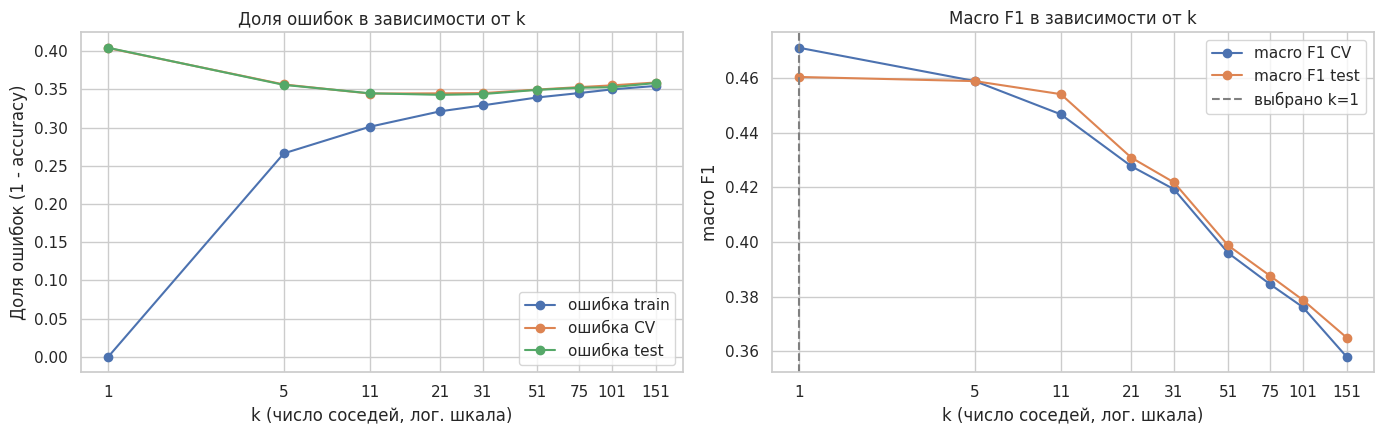

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

curve[['ошибка train', 'ошибка CV', 'ошибка test']].plot(ax=axes[0], marker='o')
axes[0].set_title('Доля ошибок в зависимости от k')
axes[0].set_ylabel('Доля ошибок (1 - accuracy)')

curve[['macro F1 CV', 'macro F1 test']].plot(ax=axes[1], marker='o')
axes[1].axvline(best_k, color='gray', ls='--', label=f'выбрано k={best_k}')
axes[1].set_title('Macro F1 в зависимости от k')
axes[1].set_ylabel('macro F1')
axes[1].legend()

for ax in axes:
    ax.set_xscale('log')
    ax.set_xticks(ks)
    ax.set_xticklabels(ks)
    ax.set_xlabel('k (число соседей, лог. шкала)')
plt.tight_layout()
plt.show()

**Вывод.** На левом графике ошибка на обучающей выборке при `k=1` почти равна нулю (0,0002): каждый объект сам себе ближайший сосед. Несколько ошибок всё же есть: это игры с полностью одинаковыми признаками, но из разных классов. С ростом `k` ошибка на train растёт, а ошибки на кросс-валидации и тесте сначала падают (с 40,4 % при `k=1` до минимума около 34,3–34,5 % при `k=11–31`), а затем медленно растут. Кривые CV и test почти совпадают, значит, кросс-валидация хорошо оценивает качество на новых данных.

На правом графике macro F1 с ростом `k` монотонно падает: от 0,47 при `k=1` до 0,36 при `k=151`. Причина в дисбалансе: чем больше соседей голосует, тем чаще среди них большинство составляют нишевые игры (их 60 %), и модель всё реже называет редкие классы. Доля ошибок при этом падает, потому что модель чаще угадывает самый частый класс.

Получается, что два критерия выбирают разные `k`: по доле ошибок лучше всего `k≈11–21`, по macro F1 лучше `k=1`. Мы выбирали по macro F1, так как нам важно различать все классы, а не только угадывать нишевые игры. Заметим, что разница между `k=1` и `k=5` по macro F1 небольшая (0,471 и 0,459 на CV), а ошибок у `k=5` на 5 процентных пунктов меньше, поэтому `k=5` — тоже разумный компромисс. Модель с `k=1` самая неустойчивая: ответ определяется одним-единственным соседом.

Обучаем kNN с выбранным $k$ и печатаем матрицы рассогласования (строки — истинный класс, столбцы — предсказанный). Ниже также отчёт по классам и матрица в процентах: какая доля игр каждого истинного класса куда попала.

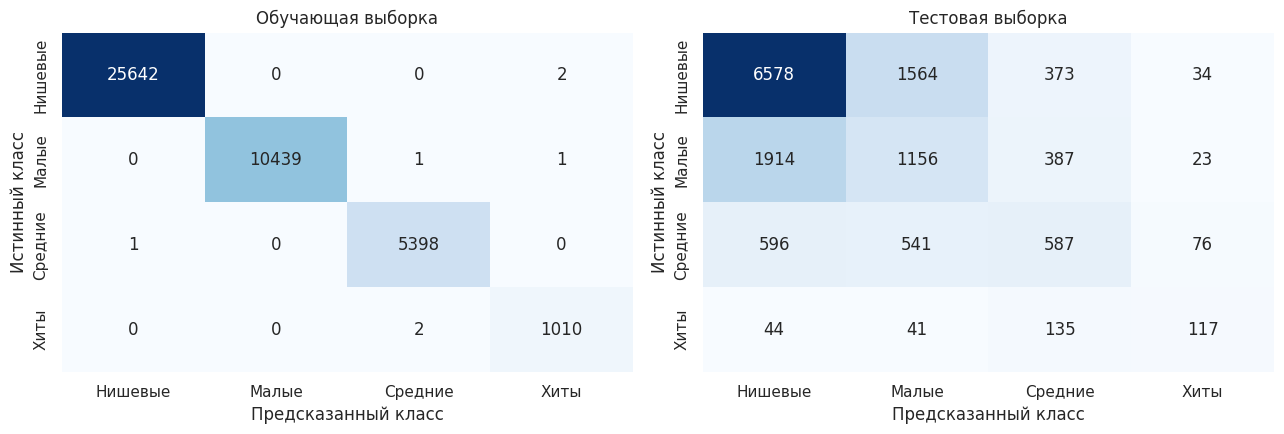

              precision    recall  f1-score   support

     Нишевые      0.720     0.769     0.744      8549
       Малые      0.350     0.332     0.341      3480
     Средние      0.396     0.326     0.358      1800
        Хиты      0.468     0.347     0.399       337

    accuracy                          0.596     14166
   macro avg      0.484     0.444     0.460     14166
weighted avg      0.582     0.596     0.588     14166

Матрица рассогласования на тесте, % от истинного класса:


,Нишевые,Малые,Средние,Хиты
Нишевые,76.9,18.3,4.4,0.4
Малые,55.0,33.2,11.1,0.7
Средние,33.1,30.1,32.6,4.2
Хиты,13.1,12.2,40.1,34.7


In [40]:
knn_best, p_best = evaluate(f'KNN, k={best_k} (выбрано по CV)',
                            KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1),
                            A_train, A_test)
p_best_train = knn_best.predict(A_train)

short = ['Нишевые', 'Малые', 'Средние', 'Хиты']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (yt, yp, title) in zip(axes, [(y_train, p_best_train, 'Обучающая выборка'),
                                      (y_test, p_best, 'Тестовая выборка')]):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=short, yticklabels=short, ax=ax)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_title(title)
plt.tight_layout()
plt.show()

print(classification_report(y_test, p_best, target_names=short, digits=3))

print('Матрица рассогласования на тесте, % от истинного класса:')
cm = confusion_matrix(y_test, p_best, normalize='true')
pd.DataFrame(cm * 100, index=short, columns=short).round(1)

**Вывод.** На обучающей выборке матрица почти диагональная (8 ошибок из 42 496). При `k=1` это ничего не говорит о качестве: объект находит самого себя.

На тестовой выборке доля верных ответов 59,6 %, macro F1 0,46.
- **Нишевые** игры модель находит хорошо: recall 0,77, precision 0,72.
- **Малые и средние** распознаются хуже всего: recall около 0,33, precision 0,35–0,40. Больше половины малых игр (55 %) модель принимает за нишевые, а средние распределены почти поровну между нишевыми, малыми и средними.
- **Хиты** найдены в 34,7 % случаев (117 из 337), при этом почти половина предсказанных хитов действительно хиты (precision 0,47). Ещё 40 % хитов модель отнесла к средним.

Важно, что ошибки в основном происходят между **соседними** классами: хит чаще принимают за среднюю игру, малую — за нишевую. Грубые ошибки редки: нишевую игру хитом назвали в 0,4 % случаев (34 игры), хит нишевой — в 13 %. Классы упорядочены, а границы между ними условные (игра с 19 и с 21 тысячей владельцев попадает в разные классы, хотя почти не отличается), поэтому ошибки на соседний класс вполне ожидаемы.

В целом по «витринным» характеристикам игры можно отделить потенциальные хиты от нишевых игр, но точно предсказать класс трудно. Популярность сильно зависит от того, чего нет в данных: качества самой игры, маркетинга, стримеров, удачи.

# 10. Другие классификаторы

Сравним kNN с тремя другими моделями:
- **логистическая регрессия** — простая линейная модель. Ей нужна нормализация, которая у нас уже есть;
- **случайный лес** — ансамбль решающих деревьев. Нормализация ему не нужна, он умеет находить нелинейные зависимости и взаимодействия признаков, а заодно показывает важность признаков;
- **градиентный бустинг** (`HistGradientBoostingClassifier`) — деревья строятся последовательно, и каждое исправляет ошибки предыдущих. Обычно это одна из самых сильных моделей для табличных данных.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

evaluate('Логистическая регрессия', LogisticRegression(max_iter=2000), A_train, A_test)

rf, _ = evaluate('Случайный лес (300 деревьев)',
                 RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                        random_state=RANDOM_STATE, n_jobs=-1),
                 A_train, A_test)

evaluate('Градиентный бустинг', HistGradientBoostingClassifier(random_state=RANDOM_STATE),
         A_train, A_test)

pd.DataFrame(results).set_index('Модель').round(3)

,ошибка train,ошибка test,balanced accuracy test,macro F1 train,macro F1 test,recall «Хиты» test
Модель,,,,,,
Всегда «Нишевая»,0.397,0.397,0.250,0.188,0.188,0.000
"KNN, k=5",0.266,0.356,0.423,0.605,0.459,0.291
"KNN, k=1 (выбрано по CV)",0.000,0.404,0.444,0.999,0.460,0.347
Логистическая регрессия,0.318,0.323,0.502,0.551,0.532,0.430
Случайный лес (300 деревьев),0.042,0.308,0.477,0.952,0.520,0.297
Градиентный бустинг,0.233,0.306,0.528,0.736,0.555,0.448


**Вывод.** Все три модели оказались лучше kNN по macro F1: логистическая регрессия 0,53, случайный лес 0,52, градиентный бустинг 0,555 (у лучшего kNN было 0,46). Доля ошибок на тесте у них около 31–32 % против 35,6–40 % у kNN.

Неожиданно хорошо сработала простая линейная модель, хотя корреляции отдельных признаков с классом слабые. Логистическая регрессия подбирает каждому признаку свой вес и складывает много слабых сигналов. kNN, наоборот, учитывает все 97 признаков с одинаковым весом, в том числе бесполезные (например, месяц выхода), и в таком многомерном пространстве «ближайшие» игры оказываются похожими не по самым важным характеристикам.

Случайный лес сильно переобучается: ошибка на обучающей выборке 4,2 %, на тестовой 30,8 %. Но на тесте он всё равно работает не хуже остальных. Градиентный бустинг переобучается меньше (23 % на train, 31 % на test) и даёт лучший macro F1 из моделей без учёта дисбаланса.

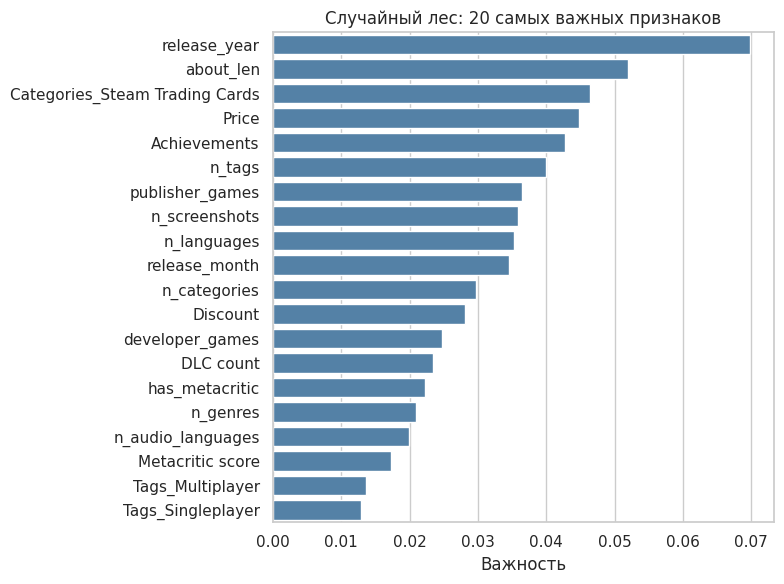

In [43]:
imp = pd.Series(rf.feature_importances_, index=A_train.columns).sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title('Случайный лес: 20 самых важных признаков')
plt.xlabel('Важность')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Вывод.** Самые важные признаки для случайного леса: год выхода, длина описания, наличие коллекционных карточек Steam (`Categories_Steam Trading Cards`), цена, число достижений и тегов, размер портфолио издателя, число скриншотов и языков. Это согласуется с анализом в пункте 3.

Две оговорки:
- **Коллекционные карточки и число тегов** частично зависят от популярности. Valve включает карточки только для игр, которые набрали определённые продажи, а теги ставят игроки. Строго говоря, эти признаки тоже содержат немного «будущей» информации. Если бы мы хотели предсказывать популярность ещё до выхода игры, их стоило бы исключить.
- **Месяц выхода** оказался на 10-м месте, хотя его корреляция с классом почти нулевая. Важность в случайном лесе по умолчанию завышает признаки с большим числом различных значений: по ним можно сделать много разбиений, и часть из них случайно уменьшает «нечистоту». Скорее всего, месяц выхода на самом деле почти бесполезен.

**Текстовый признак.** До сих пор от описания игры мы использовали только его длину. Попробуем использовать сам текст. Метод **TF-IDF** превращает каждое описание в вектор: для каждого слова (и пары слов) он показывает, насколько это слово характерно именно для этого описания. Частые во всех текстах слова получают маленький вес, специфичные — большой. HTML-теги из описаний предварительно удаляем.

Сначала обучим логистическую регрессию только на тексте, затем на тексте вместе со всеми остальными признаками. Словарь TF-IDF строим только по обучающей выборке.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix


def clean_text(s):
    """Убираем HTML-теги и спецсимволы вида &quot;."""
    return (s.fillna('').str.replace(r'<[^>]+>', ' ', regex=True)
             .str.replace(r'&[a-z]+;', ' ', regex=True))


tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5,
                        stop_words='english', sublinear_tf=True)
T_train = tfidf.fit_transform(clean_text(train['About the game']))
T_test = tfidf.transform(clean_text(test['About the game']))
print('Размер матрицы TF-IDF:', T_train.shape)

evaluate('TF-IDF описания + логрегрессия', LogisticRegression(max_iter=2000), T_train, T_test)

# объединяем табличные признаки и текст в одну (разреженную) матрицу
AT_train = hstack([csr_matrix(A_train.values), T_train]).tocsr()
AT_test = hstack([csr_matrix(A_test.values), T_test]).tocsr()
evaluate('Признаки + TF-IDF, логрегрессия', LogisticRegression(max_iter=2000), AT_train, AT_test)

pd.DataFrame(results).set_index('Модель').round(3)

Размер матрицы TF-IDF: (42496, 20000)


,ошибка train,ошибка test,balanced accuracy test,macro F1 train,macro F1 test,recall «Хиты» test
Модель,,,,,,
Всегда «Нишевая»,0.397,0.397,0.250,0.188,0.188,0.000
"KNN, k=5",0.266,0.356,0.423,0.605,0.459,0.291
"KNN, k=1 (выбрано по CV)",0.000,0.404,0.444,0.999,0.460,0.347
Логистическая регрессия,0.318,0.323,0.502,0.551,0.532,0.430
Случайный лес (300 деревьев),0.042,0.308,0.477,0.952,0.520,0.297
Градиентный бустинг,0.233,0.306,0.528,0.736,0.555,0.448
TF-IDF описания + логрегрессия,0.283,0.393,0.314,0.519,0.318,0.059
"Признаки + TF-IDF, логрегрессия",0.217,0.327,0.509,0.720,0.539,0.448


**Вывод.** Описание игры само по себе даёт слабый результат: логистическая регрессия только на TF-IDF получает macro F1 0,32 и почти не находит хиты (recall 0,06). Вместе с остальными признаками текст немного улучшает модель: macro F1 0,539 против 0,532 без текста. Эффект небольшой, но заметный. Похоже, слова в описании отражают жанр и стиль игры, а эта информация уже частично есть в тегах и жанрах. Ошибка на обучающей выборке при этом заметно падает (21,7 % против 31,8 %), то есть модель с 20 000 признаками текста начинает подстраиваться под обучающие данные.

# 11. Борьба с несбалансированностью классов

Классы распределены как 60 / 25 / 13 / 2, и модели склонны «не замечать» редкие классы. Попробуем два способа:
- **веса классов** (`class_weight='balanced'`): ошибка на объекте редкого класса штрафуется сильнее, обратно пропорционально размеру класса. Это поддерживают логистическая регрессия, случайный лес и градиентный бустинг;
- **oversampling** для kNN (весов классов kNN не поддерживает): в обучающей выборке случайно дублируем объекты редких классов, пока все классы не сравняются по размеру. Дублируем **только train**, иначе копии попали бы в тест и оценка была бы завышена. При `k=1` дублирование ничего не меняет (ближайший сосед остаётся тем же), поэтому берём `k = 5, 11, 21`.

In [45]:
evaluate('Логрегрессия, class_weight=balanced',
         LogisticRegression(max_iter=2000, class_weight='balanced'), A_train, A_test)

evaluate('Случайный лес, class_weight=balanced',
         RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE,
                                n_jobs=-1, class_weight='balanced_subsample'),
         A_train, A_test)

evaluate('Градиентный бустинг, class_weight=balanced',
         HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
         A_train, A_test)

evaluate('Признаки + TF-IDF, логрегрессия, balanced',
         LogisticRegression(max_iter=2000, class_weight='balanced'), AT_train, AT_test)

# random oversampling: дублируем объекты редких классов (только train)
rng = np.random.RandomState(RANDOM_STATE)
n_max = y_train.value_counts().max()
idx = np.concatenate([rng.choice(np.where(y_train.values == c)[0], n_max,
                                 replace=(y_train == c).sum() < n_max)
                      for c in sorted(y_train.unique())])
A_over, y_over = A_train.iloc[idx], y_train.iloc[idx]
print('Размеры классов после oversampling:', y_over.value_counts().sort_index().tolist())

for k in [5, 11, 21]:
    evaluate(f'KNN, k={k}, oversampling', KNeighborsClassifier(n_neighbors=k, n_jobs=-1),
             A_train, A_test, fit_data=(A_over, y_over))

pd.DataFrame(results).set_index('Модель').round(3)

Размеры классов после oversampling: [25644, 25644, 25644, 25644]


,ошибка train,ошибка test,balanced accuracy test,macro F1 train,macro F1 test,recall «Хиты» test
Модель,,,,,,
Всегда «Нишевая»,0.397,0.397,0.250,0.188,0.188,0.000
"KNN, k=5",0.266,0.356,0.423,0.605,0.459,0.291
"KNN, k=1 (выбрано по CV)",0.000,0.404,0.444,0.999,0.460,0.347
Логистическая регрессия,0.318,0.323,0.502,0.551,0.532,0.430
Случайный лес (300 деревьев),0.042,0.308,0.477,0.952,0.520,0.297
Градиентный бустинг,0.233,0.306,0.528,0.736,0.555,0.448
TF-IDF описания + логрегрессия,0.283,0.393,0.314,0.519,0.318,0.059
"Признаки + TF-IDF, логрегрессия",0.217,0.327,0.509,0.720,0.539,0.448
"Логрегрессия, class_weight=balanced",0.382,0.382,0.600,0.528,0.521,0.777


**Вывод.** Веса классов меняют поведение моделей одинаково: доля найденных хитов резко растёт, а доля ошибок тоже растёт, потому что модель чаще называет игры хитами и средними и при этом чаще ошибается.
- **Логистическая регрессия:** recall хитов вырос с 0,43 до 0,78, balanced accuracy с 0,50 до 0,60, но ошибка выросла с 32,3 % до 38,2 %, а macro F1 немного снизился (0,521 против 0,532).
- **Градиентный бустинг:** recall хитов с 0,45 до 0,70, balanced accuracy с 0,53 до 0,61 (лучший результат среди всех моделей), macro F1 почти не изменился (0,558), ошибка выросла с 30,6 % до 35,7 %.
- **Случайный лес:** выиграл больше всех: macro F1 вырос с 0,52 до 0,576 (лучший результат в работе), recall хитов с 0,30 до 0,49, при этом доля ошибок не изменилась (30,6 %).

**kNN с oversampling.** Дублирование редких классов позволяет брать больше соседей, не теряя редкие классы. Лучший вариант (`k=11`) даёт macro F1 0,469 против 0,460 у обычного kNN, при `k=21` находится 61 % хитов вместо 35 %. Но доля ошибок растёт до 43–45 %: модель часто относит нишевые игры к более популярным классам.

Какой вариант лучше, зависит от цели. Если нужно найти как можно больше потенциальных хитов (например, издателю, который ищет проекты для поддержки), подходят модели с весами классов: ложная тревога стоит дешевле, чем пропущенный хит. Если важна общая доля верных ответов, лучше модели без весов.

# 12. Исключение коррелированных переменных

Сильно коррелированные признаки несут почти одну и ту же информацию. Для kNN это вредно: расстояние считается по всем признакам сразу, и дублирующая информация фактически получает двойной вес. Для линейных моделей сильная корреляция вызывает мультиколлинеарность (коэффициенты становятся неустойчивыми). Деревьям она почти не мешает. Кроме того, меньше признаков означает быстрее счёт.

Найдём пары признаков итоговой матрицы с |корреляцией| > 0,8 (по обучающей выборке) и из каждой пары удалим второй признак.

In [48]:
c = A_train.corr().abs()
cols = list(A_train.columns)
pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(cols) for b in cols[i + 1:] if c.loc[a, b] > 0.8]
pairs_df = (pd.DataFrame(pairs, columns=['признак 1', 'признак 2', '|корреляция|'])
              .sort_values('|корреляция|', ascending=False))
display(pairs_df.round(3))

drop_cols = sorted(set(pairs_df['признак 2']))
A_train_r = A_train.drop(columns=drop_cols)
A_test_r = A_test.drop(columns=drop_cols)
print('Удаляем:', drop_cols)
print('Признаков было:', A_train.shape[1], ', стало:', A_train_r.shape[1])

ks = [1, 5, 11, 21]          # меньше вариантов k, чтобы считалось быстрее
curve_r = knn_curve(A_train_r, A_test_r)
best_k_r = int(curve_r['macro F1 CV'].idxmax())
print('Лучшее k по кросс-валидации без коррелированных признаков:', best_k_r)
display(curve_r.round(4))

evaluate(f'KNN, k={best_k_r}, без коррел. признаков',
         KNeighborsClassifier(n_neighbors=best_k_r, n_jobs=-1), A_train_r, A_test_r)
_=evaluate('Градиентный бустинг, balanced, без коррел. признаков',
         HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
         A_train_r, A_test_r)

,признак 1,признак 2,|корреляция|
10,Categories_Remote Play on Phone,Categories_Remote Play on Tablet,0.905
1,is_free,Categories_Family Sharing,0.890
5,Genres_RPG,Tags_RPG,0.886
7,Genres_Strategy,Tags_Strategy,0.880
2,Genres_Action,Tags_Action,0.879
11,Categories_Tracked Controller Support,Categories_VR Only,0.869
6,Genres_Simulation,Tags_Simulation,0.867
8,Categories_Online PvP,Categories_PvP,0.838
9,Categories_Remote Play Together,Categories_Shared/Split Screen,0.832
4,Genres_Casual,Tags_Casual,0.832


Удаляем: ['Categories_Family Sharing', 'Categories_PvP', 'Categories_Remote Play on Tablet', 'Categories_Shared/Split Screen', 'Categories_Steam Achievements', 'Categories_VR Only', 'Tags_Action', 'Tags_Adventure', 'Tags_Casual', 'Tags_RPG', 'Tags_Simulation', 'Tags_Strategy']
Признаков было: 97 , стало: 85
k =   1 готово
k =   5 готово
k =  11 готово
k =  21 готово
Лучшее k по кросс-валидации без коррелированных признаков: 1


,ошибка train,ошибка CV,ошибка test,macro F1 CV,macro F1 test
k,,,,,
1,0.0002,0.4068,0.4046,0.4647,0.4636
5,0.2656,0.3559,0.3527,0.4601,0.4607
11,0.3020,0.3459,0.3460,0.4480,0.4543
21,0.3196,0.3427,0.3410,0.4322,0.4352


**Вывод.** Найдено 12 пар признаков с |корреляцией| > 0,8. Почти все они ожидаемые:
- **жанр и одноимённый тег** (RPG, Strategy, Action, Simulation, Casual, Adventure; 0,81–0,89): жанр указывает разработчик, тег ставят игроки, но обычно они совпадают;
- **похожие категории Steam:** Remote Play на телефоне и планшете (0,905), VR Only и поддержка VR-контроллеров (0,869), Online PvP и PvP (0,838), Remote Play Together и Shared/Split Screen (0,832);
- **бесплатная игра и Family Sharing** (0,890): семейный доступ работает только для платных игр;
- **число достижений и категория «Steam Achievements»** (0,816).

После удаления 12 признаков (было 97, стало 85) качество kNN немного улучшилось: macro F1 на тесте 0,464 против 0,460 при `k=1` и 0,461 против 0,459 при `k=5`. Оптимальное `k` осталось прежним. Для градиентного бустинга результат практически не изменился (0,553 против 0,558): деревьям дублирующие признаки почти не мешают. Итог — то же качество на более простой модели. Для kNN выигрыш небольшой, потому что удалённые признаки бинарные и мало влияли на расстояние по сравнению с 85 оставшимися.

# 13. Сводная таблица и общие выводы

,ошибка train,ошибка test,balanced accuracy test,macro F1 train,macro F1 test,recall «Хиты» test
Модель,,,,,,
"Случайный лес, class_weight=balanced",0.011,0.306,0.549,0.986,0.576,0.490
"Градиентный бустинг, class_weight=balanced",0.307,0.357,0.608,0.656,0.558,0.703
Градиентный бустинг,0.233,0.306,0.528,0.736,0.555,0.448
"Градиентный бустинг, balanced, без коррел. признаков",0.308,0.358,0.603,0.653,0.553,0.685
"Признаки + TF-IDF, логрегрессия",0.217,0.327,0.509,0.720,0.539,0.448
Логистическая регрессия,0.318,0.323,0.502,0.551,0.532,0.430
"Признаки + TF-IDF, логрегрессия, balanced",0.232,0.379,0.569,0.760,0.532,0.626
"Логрегрессия, class_weight=balanced",0.382,0.382,0.600,0.528,0.521,0.777
Случайный лес (300 деревьев),0.042,0.308,0.477,0.952,0.520,0.297


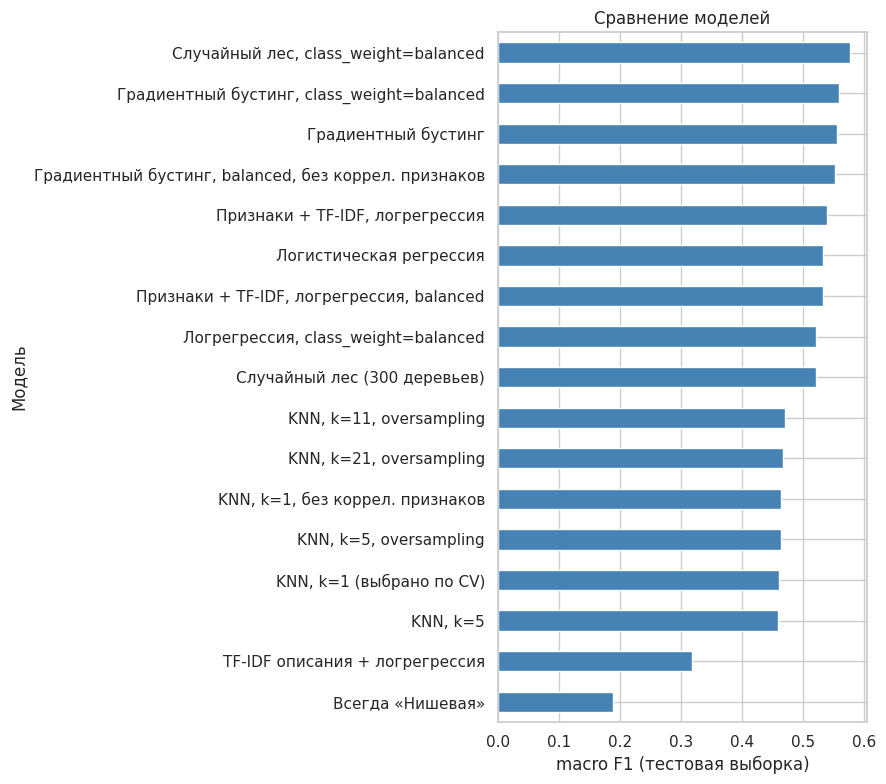

In [47]:
summary = pd.DataFrame(results).set_index('Модель').sort_values('macro F1 test', ascending=False)
display(summary.round(3))

plt.figure(figsize=(9, 8))
summary['macro F1 test'].sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('macro F1 (тестовая выборка)')
plt.title('Сравнение моделей')
plt.tight_layout()
plt.show()

## Общие выводы

1. **Задача.** По 56 662 играм Steam (с хотя бы 10 отзывами) решалась задача классификации числа владельцев на 4 класса: нишевые (до 20 тыс.), малые (20–100 тыс.), средние (0,1–1 млн) и хиты (больше 1 млн). Классы сильно несбалансированы (60 / 25 / 13 / 2 %), поэтому качество оценивалось не только по доле ошибок, но и по macro F1, balanced accuracy и полноте класса «Хиты». Тривиальный классификатор «всегда нишевая» ошибается в 39,7 % случаев, но не находит ни одной популярной игры (macro F1 0,19).

2. **Утечка целевой переменной.** Число отзывов, рекомендаций, пиковый онлайн и время игры связаны с классом очень сильно (корреляция до 0,65), потому что число владельцев оценивается в основном по отзывам. Эти признаки являются следствием популярности, а не причиной, поэтому мы их исключили и обучали модели только на информации со страницы игры в магазине.

3. **Данные.** Больше шансов стать популярной у игр, которые вышли раньше, переведены на много языков, выпущены крупным издателем, поддерживают Mac и Linux, имеют сайт и оценку Metacritic, многопользовательский режим, а также у бесплатных и MMO-игр. Казуальные, инди- и игры в раннем доступе чаще остаются нишевыми. Каждый признак в отдельности связан с классом слабо (|корреляция| не больше 0,34).

4. **Подготовка данных.** Исправлен сдвиг столбцов в исходном CSV. Найдены скрытые пропуски (нулевая оценка Metacritic) и обработаны с сохранением информации о пропуске. Выбросы не удалялись, так как среди них больше популярных игр, а были обрезаны по 99-му процентилю. Разработчик и издатель закодированы размером портфолио, жанры, теги и категории — multi-hot кодированием. Числовые признаки прологарифмированы и стандартизованы. Все параметры обработки считались только по обучающей выборке.

5. **Метод ближайших соседей.** Лучшее `k` по кросс-валидации (macro F1) равно 1: macro F1 0,46 на тесте, ошибка 40,4 %. По доле ошибок оптимальны `k≈11–21` (ошибка около 34,3 %), но тогда модель почти не называет редкие классы. kNN хорошо отличает нишевые игры (recall 0,77), находит около трети хитов, а ошибается в основном на соседний класс.

6. **Сравнение моделей.** Логистическая регрессия, случайный лес и градиентный бустинг работают заметно лучше kNN (macro F1 0,52–0,58). Лучший результат по macro F1 у случайного леса с весами классов (0,576). По balanced accuracy (0,61) лучший градиентный бустинг с весами классов, он находит 70 % хитов. kNN страдает от большого числа признаков с одинаковым весом.

7. **Дисбаланс.** Веса классов и oversampling сильно повышают долю найденных хитов (у логистической регрессии с 43 % до 78 %), но увеличивают число ложных срабатываний. Выбор зависит от того, что важнее: найти потенциальные хиты или ошибаться реже в целом.

8. **Текст и коррелированные признаки.** Описание игры (TF-IDF) само по себе предсказывает плохо, а вместе с остальными признаками даёт небольшой прирост. Удаление 12 сильно коррелированных признаков сохранило качество при меньшем числе признаков.

9. **Главный вывод.** По оформлению страницы в магазине можно отделить потенциально популярные игры от нишевых заметно лучше случайного угадывания, но точно предсказать класс нельзя: лучшая модель ошибается примерно в 30 % случаев. Популярность сильно зависит от факторов, которых нет в данных: качества самой игры, маркетинга, стримеров.